# S&P 500 forecasting with Transformer (PatchTST)

Dataset: `CSV/S&P 500 Historical Data.csv`. Target: source `Price`, closing **index points** (not USD or total-return index). Only Price-derived returns enter the model; Volume is optional and unused.

**Framework:** schema/calendar checks -> descriptive EDA -> raw chronological 80/20 split -> Train-only preprocessing and windows -> fixed/reference Train-only configuration and training -> rolling-origin Test forecasts with frozen model/scalers -> full horizon tables -> latest-origin future forecasts -> RMSE/MAPE in original units and plots -> model-specific assumptions/diagnostics -> result-generated summary.

**Horizons:** 1, 3, 5, 7, 14, 21, 30 **NYSE trading sessions**, consistent with the S&P ARIMA task. Lookback=60 past session returns follows the requested model example; 30 sessions is not called a month. MIMO: predict the next 30 individual session returns, average predicted returns across five predefined seeds, then compound to each horizon.

**Fixed design:** PyTorch PatchTST with the reference patch encoder, RevIN, BatchNorm and residual attention; 100 fixed epochs, Adam max LR 1e-4, fixed OneCycleLR, batch 128; seeds [0,1,2,3,4]. No validation, cross-validation, Test tuning, early stopping, seed/checkpoint selection or all-data refit. All training targets stay inside Train. Observed history advances rolling inputs only.

**Run:** existing `vs_nine_tf` environment, `C:/Users/User/anaconda3/envs/vs_nine_tf/python.exe`, Python 3 (ipykernel), Restart Kernel and Run All Cells. To launch from the project root: `& 'C:\Users\User\anaconda3\envs\vs_nine_tf\python.exe' -m jupyter lab`. The first code cell prints the actual Python executable and library versions.

**Output:** only this existing notebook is saved; complete forecast/diagnostic tables, figures and summary are embedded. Fitted models/scalers live in memory while the kernel runs; no additional notebook, CSV/PNG/model/summary files are written. Reference: `BTC_TEST/TRANSFORMER_BTC.ipynb`.

**Assumption checks:** Step 11 separates Group A process invariants from Group B reporting-only h=1 residual diagnostics. These estimators do not require ARIMA root conditions or stationary levels.


## Step 1 - Environment setup and fixed configuration
CPU is the default. Seed Python, NumPy and PyTorch; enable deterministic algorithms. Model/training configuration is checked against the official ETTh1 script and parser. BTC task settings such as 60-session lookback and 30-session output remain the user's explicit data design.

The reference experiment has a different lookback, targets, data frequency and seed. It is a source for model settings, not permission to alter this BTC experiment or introduce validation. See the generated `hyperparameter_sources.md`.

In [1]:
from pathlib import Path
import sys
import json
import warnings
from importlib.metadata import version
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import hashlib
import time
import random
import sklearn
from sklearn.preprocessing import StandardScaler
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torch.optim import Adam
from torch.optim.lr_scheduler import OneCycleLR
import statsmodels
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.stattools import jarque_bera
import scipy
from scipy import stats
from IPython.display import display, Markdown, HTML

DATA_PATH = Path('CSV') / 'S&P 500 Historical Data.csv'
HORIZONS = [1, 3, 5, 7, 14, 21, 30]
DAILY_FORECAST_WINDOWS = [7, 30]
MAX_H = max(HORIZONS)
TRAIN_RATIO = 0.8
LOOKBACK = 60
SEEDS = [0, 1, 2, 3, 4]
PATCH_LEN = 16
STRIDE = 8
PADDING_PATCH = 'end'
N_LAYERS = 3
N_HEADS = 4
D_MODEL = 16
D_FF = 128
DROPOUT = 0.3
FC_DROPOUT = 0.3
HEAD_DROPOUT = 0.0
REVIN = True
LR = 1e-4
BATCH_SIZE = 128
EPOCHS = 100
PCT_START = 0.3
DEVICE = torch.device('cpu')

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

# One CPU thread avoids oversubscription for this small network.
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
set_seed(SEEDS[0])
ALPHA = 0.05
assert max(HORIZONS) == MAX_H
from pandas.tseries.holiday import (AbstractHolidayCalendar, Holiday,
    USMartinLutherKingJr, USPresidentsDay, GoodFriday, USMemorialDay,
    USLaborDay, USThanksgivingDay, nearest_workday, sunday_to_monday)

MODEL_LABEL = 'Transformer (PatchTST)'
TARGET_COLUMN = 'Price'
DATE_FORMAT = '%m/%d/%Y'
TARGET_UNITS = 'index points'
HORIZON_UNIT = 'trading sessions'
CALENDAR_START_YEAR, CALENDAR_END_YEAR = 2021, 2027
search_dirs = [Path.cwd(), *Path.cwd().parents]
DATA_PATH = next((base/DATA_PATH for base in search_dirs if (base/DATA_PATH).is_file()), DATA_PATH)
if not DATA_PATH.is_file(): raise FileNotFoundError('Set DATA_PATH to CSV/S&P 500 Historical Data.csv')
DATA_PATH = DATA_PATH.resolve()
# Date-only NYSE closure rules for this dataset's 2021-2027 range.
# Saturday New Year's Day does NOT close the preceding Friday.
class NYSESessionHolidays(AbstractHolidayCalendar):
    rules = [Holiday('New Year', month=1, day=1, observance=sunday_to_monday),
        USMartinLutherKingJr, USPresidentsDay, GoodFriday, USMemorialDay,
        Holiday('Juneteenth', month=6, day=19, start_date='2022-01-01', observance=nearest_workday),
        Holiday('Independence Day', month=7, day=4, observance=nearest_workday),
        USLaborDay, USThanksgivingDay,
        Holiday('Christmas', month=12, day=25, observance=nearest_workday),
        Holiday('National Day of Mourning', year=2025, month=1, day=9)]
calendar_holidays = NYSESessionHolidays().holidays(
    f'{CALENDAR_START_YEAR}-01-01', f'{CALENDAR_END_YEAR}-12-31')
def nyse_sessions(start, end):
    start, end = pd.Timestamp(start).normalize(), pd.Timestamp(end).normalize()
    if not (CALENDAR_START_YEAR <= start.year <= end.year <= CALENDAR_END_YEAR):
        raise ValueError('Extend/recheck the NYSE calendar before using dates outside 2021-2027.')
    return pd.bdate_range(start, end).difference(calendar_holidays)


notebook_tables = {}
notebook_figures = []
def save_table(frame, name):
    notebook_tables[name] = frame.copy(deep=True)
def save_figure(fig, name):
    fig.tight_layout()
    notebook_figures.append(name)
    plt.show()
    plt.close(fig)
def show_scroll_table(frame):
    display(HTML('<div style="max-height:360px;overflow:auto;border:1px solid #ddd;padding:8px">'
        + frame.to_html(index=False, float_format=lambda x: f'{x:,.4f}') + '</div>'))
def scaler_digest(scaler):
    digest=hashlib.sha256()
    for name in ['mean_', 'scale_', 'var_', 'n_samples_seen_']:
        digest.update(name.encode())
        digest.update(np.ascontiguousarray(getattr(scaler,name)).tobytes())
    return digest.hexdigest()

plt.rcParams.update({'figure.figsize':(12,5),'axes.grid':True,'grid.alpha':0.25,'figure.dpi':110})
versions = pd.DataFrame([(name,version(name)) for name in ['pandas','numpy','matplotlib','scikit-learn','statsmodels','scipy','torch']],columns=['library','version'])
print('Python:',sys.version,'\nExecutable:',sys.executable,'\nData:',DATA_PATH)
print('Horizons:',HORIZONS,HORIZON_UNIT,'; output: existing notebook only')
display(versions)
save_table(versions,'library_versions.csv')
configuration={name:globals()[name] for name in ['HORIZONS', 'MAX_H', 'LOOKBACK', 'TRAIN_RATIO', 'ALPHA', 'EPOCHS', 'BATCH_SIZE', 'LR', 'DROPOUT', 'SEEDS', 'PATCH_LEN', 'STRIDE', 'PADDING_PATCH', 'N_LAYERS', 'N_HEADS', 'D_MODEL', 'D_FF', 'FC_DROPOUT', 'HEAD_DROPOUT', 'REVIN', 'PCT_START', 'DEVICE']}
configuration.update(asset='S&P 500', target=TARGET_COLUMN, units=TARGET_UNITS, horizon_unit=HORIZON_UNIT, validation=False, output_mode='notebook only', source_reference='BTC_TEST/TRANSFORMER_BTC.ipynb')
display(pd.DataFrame([(k,str(v)) for k,v in configuration.items()],columns=['setting','value']))
assert max(DAILY_FORECAST_WINDOWS) <= max(HORIZONS)


Python: 3.12.14 | packaged by Anaconda, Inc. | (main, Aug 27 2026, 14:37:13) [MSC v.1942 64 bit (AMD64)] 
Executable: C:\Users\User\anaconda3\envs\vs_nine_tf\python.exe 
Data: C:\Users\User\Desktop\PROJECT_2026\CSV\S&P 500 Historical Data.csv
Horizons: [1, 3, 5, 7, 14, 21, 30] trading sessions ; output: existing notebook only


,library,version
0,pandas,2.3.3
1,numpy,2.5.3
2,matplotlib,3.11.1
3,scikit-learn,1.9.1
4,statsmodels,0.15.0
5,scipy,1.18.1
6,torch,2.14.1+cpu


,setting,value
0,HORIZONS,"[1, 3, 5, 7, 14, 21, 30]"
1,MAX_H,30
2,LOOKBACK,60
3,TRAIN_RATIO,0.8
4,ALPHA,0.05
5,EPOCHS,100
6,BATCH_SIZE,128
7,LR,0.0001
8,DROPOUT,0.3
9,SEEDS,"[0, 1, 2, 3, 4]"


### Configuration provenance: source notebook versus S&P task settings

In [2]:
provenance_rows=[]
for name,value in configuration.items():
    role='S&P task setting' if name in ['asset','target','units','horizon_unit','output_mode'] else 'Reference design / shared protocol'
    provenance_rows.append(dict(setting=name,value=str(value),provenance=role))
configuration_provenance=pd.DataFrame(provenance_rows)
save_table(configuration_provenance,'configuration_provenance.csv')
display(configuration_provenance)
print('Model architecture and fixed training settings follow the local BTC PatchTST notebook; no external study validation/tuning scheme is adopted.')

,setting,value,provenance
0,HORIZONS,"[1, 3, 5, 7, 14, 21, 30]",Reference design / shared protocol
1,MAX_H,30,Reference design / shared protocol
2,LOOKBACK,60,Reference design / shared protocol
3,TRAIN_RATIO,0.8,Reference design / shared protocol
4,ALPHA,0.05,Reference design / shared protocol
5,EPOCHS,100,Reference design / shared protocol
6,BATCH_SIZE,128,Reference design / shared protocol
7,LR,0.0001,Reference design / shared protocol
8,DROPOUT,0.3,Reference design / shared protocol
9,SEEDS,"[0, 1, 2, 3, 4]",Reference design / shared protocol


Model architecture and fixed training settings follow the local BTC PatchTST notebook; no external study validation/tuning scheme is adopted.


## Step 2 - Data preparation and NYSE calendar checks

Retain all observations, parse source strings and sort chronologically. Positive finite target values are required for log returns. Missing Volume remains missing and is unused. No target imputation or `.asfreq('D')` insertion of weekends/holidays. NYSE date-only rules cover 2021-2027 including 9 January 2025; early-close days count as sessions. Calendar sources are linked at the end.

In [3]:
raw = pd.read_csv(DATA_PATH, dtype=str)
required = ['Date', TARGET_COLUMN]
assert set(required).issubset(raw.columns), 'Missing Date/Price columns'
df = raw.copy()
df['Date'] = pd.to_datetime(df['Date'], format=DATE_FORMAT, errors='raise')
assert not df['Date'].isna().any() and not df['Date'].duplicated().any(), 'Missing/duplicate dates'
df = df.sort_values('Date').set_index('Date')
for col in ['Price', 'Open', 'High', 'Low']:
    if col in df:
        df[col] = pd.to_numeric(df[col].str.replace(',', '', regex=False), errors='raise')
        assert df[col].notna().all() and np.isfinite(df[col]).all(), f'Invalid {col}'
if 'Change %' in df:
    df['Change %'] = pd.to_numeric(df['Change %'].str.replace('%','',regex=False), errors='raise') / 100
vol_text = df.get('Vol.', pd.Series(index=df.index, dtype=str)).fillna('').str.strip().str.upper().str.replace(',','',regex=False)
volume_missing = vol_text.isin(['','-'])
parts = vol_text[~volume_missing].str.extract(r'^(?P<number>\d+(?:\.\d+)?)(?P<suffix>[KMB]?)$')
assert parts.notna().all().all(), 'Unrecognized nonmissing volume format'
df['Volume'] = np.nan
df.loc[~volume_missing, 'Volume'] = pd.to_numeric(parts['number']) * parts['suffix'].map({'':1.,'K':1e3,'M':1e6,'B':1e9})
b_rows = df.loc[vol_text.str.endswith('B')].copy()
expected_sessions = nyse_sessions(df.index[0], df.index[-1])
missing_sessions = expected_sessions.difference(df.index)
unexpected_dates = df.index.difference(expected_sessions)
calendar_audit = pd.DataFrame([dict(check='Expected sessions missing', count=len(missing_sessions), dates=str(list(missing_sessions.date))),
    dict(check='Unexpected/non-session dates', count=len(unexpected_dates), dates=str(list(unexpected_dates.date))),
    dict(check='Missing volume (optional)', count=int(volume_missing.sum()), dates='Retained; not a model input'),
    dict(check='Volume B rows', count=len(b_rows), dates='Retained for source review')])
display(calendar_audit)
assert not len(missing_sessions) and not len(unexpected_dates), 'Resolve session/target gaps before modeling; no imputation'
assert df.index.is_unique and df.index.is_monotonic_increasing
assert df['Price'].notna().all() and np.isfinite(df['Price']).all() and (df['Price']>0).all()
log_price = np.log(df['Price']).rename('log_price')
log_ret = log_price.diff().rename('log_ret')
assert pd.isna(log_ret.iloc[0]) and np.isfinite(log_ret.iloc[1:]).all()
save_table(calendar_audit, 'calendar_audit.csv')
save_table(b_rows, 'volume_B_rows.csv')
print(f'{len(df):,} observed sessions: {df.index[0].date()} to {df.index[-1].date()}')
print(f'Missing volume: {volume_missing.sum():,}; Volume is unused by this univariate return model.')
display(df.head())
future_dates = nyse_sessions(df.index[-1]+pd.Timedelta(days=1), df.index[-1]+pd.Timedelta(days=MAX_H*3+30))[:MAX_H]
assert len(future_dates)==MAX_H

,check,count,dates
0,Expected sessions missing,0,[]
1,Unexpected/non-session dates,0,[]
2,Missing volume (optional),1313,Retained; not a model input
3,Volume B rows,0,Retained for source review


1,313 observed sessions: 2021-07-01 to 2026-09-23
Missing volume: 1,313; Volume is unused by this univariate return model.


,Price,Open,High,Low,Vol.,Change %,Volume
Date,,,,,,,
2021-07-01,4319.9,4300.7,4320.7,4300.7,NaN,0.0052,NaN
2021-07-02,4352.3,4326.6,4355.4,4326.6,NaN,0.0075,NaN
2021-07-06,4343.5,4356.5,4356.5,4314.4,NaN,-0.0020,NaN
2021-07-07,4358.1,4351.0,4361.9,4329.8,NaN,0.0034,NaN
2021-07-08,4320.8,4321.1,4330.9,4289.4,NaN,-0.0086,NaN


C:\Users\User\AppData\Local\Temp\ipykernel_6572\2304882984.py:40: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  future_dates = nyse_sessions(df.index[-1]+pd.Timedelta(days=1), df.index[-1]+pd.Timedelta(days=MAX_H*3+30))[:MAX_H]


## Step 3 - EDA (Descriptive Only; No Model Decisions)


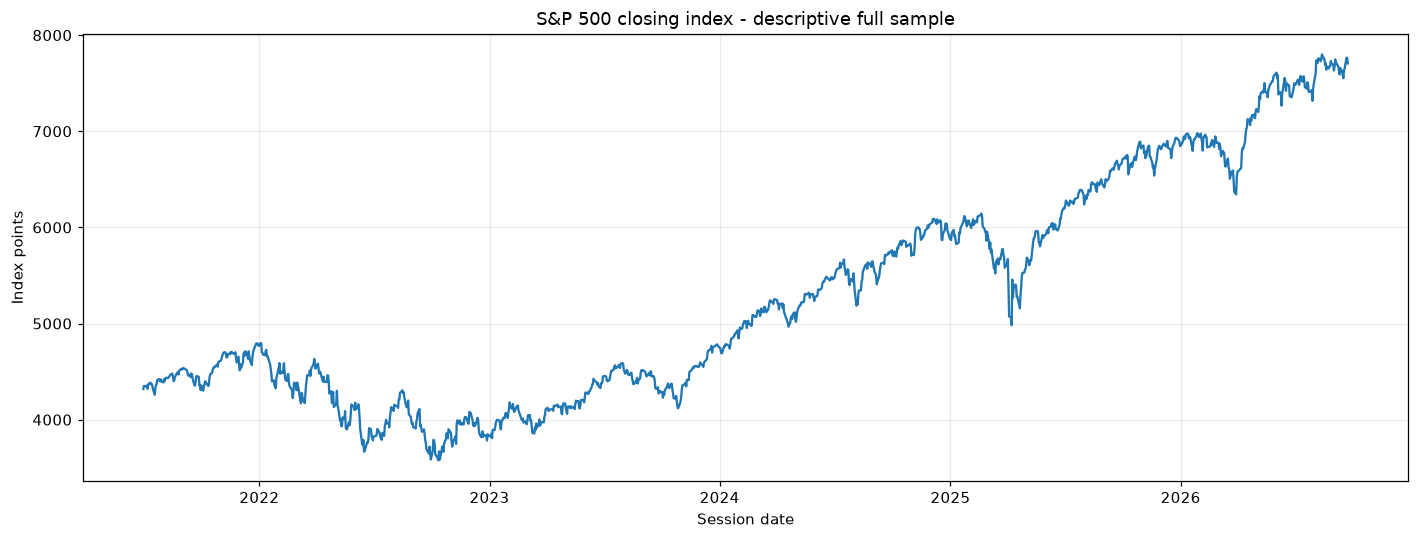

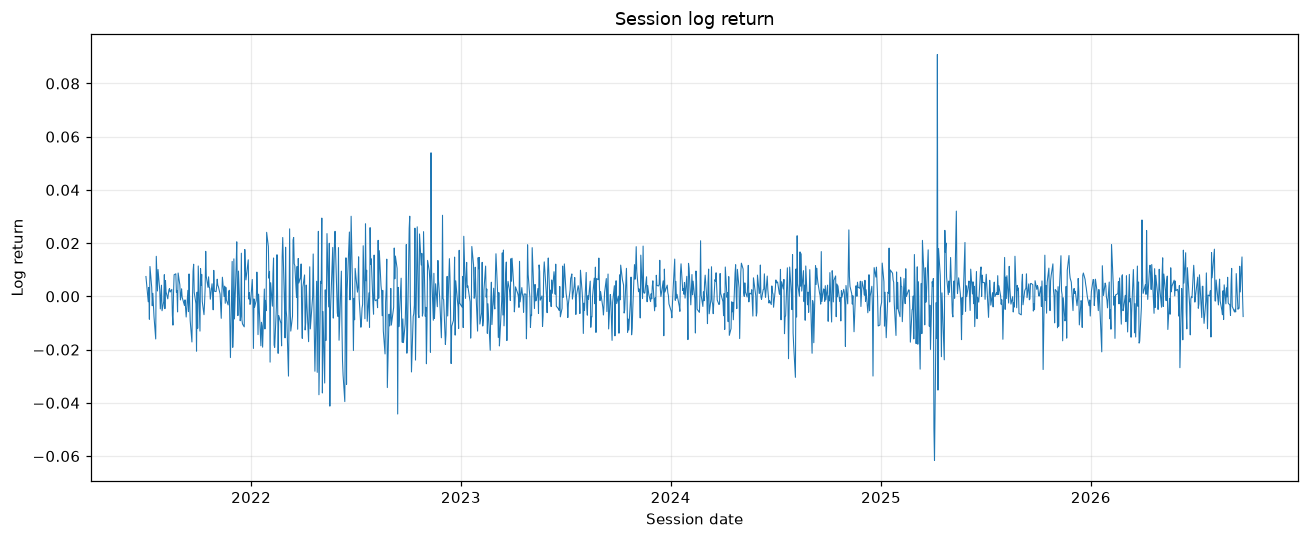

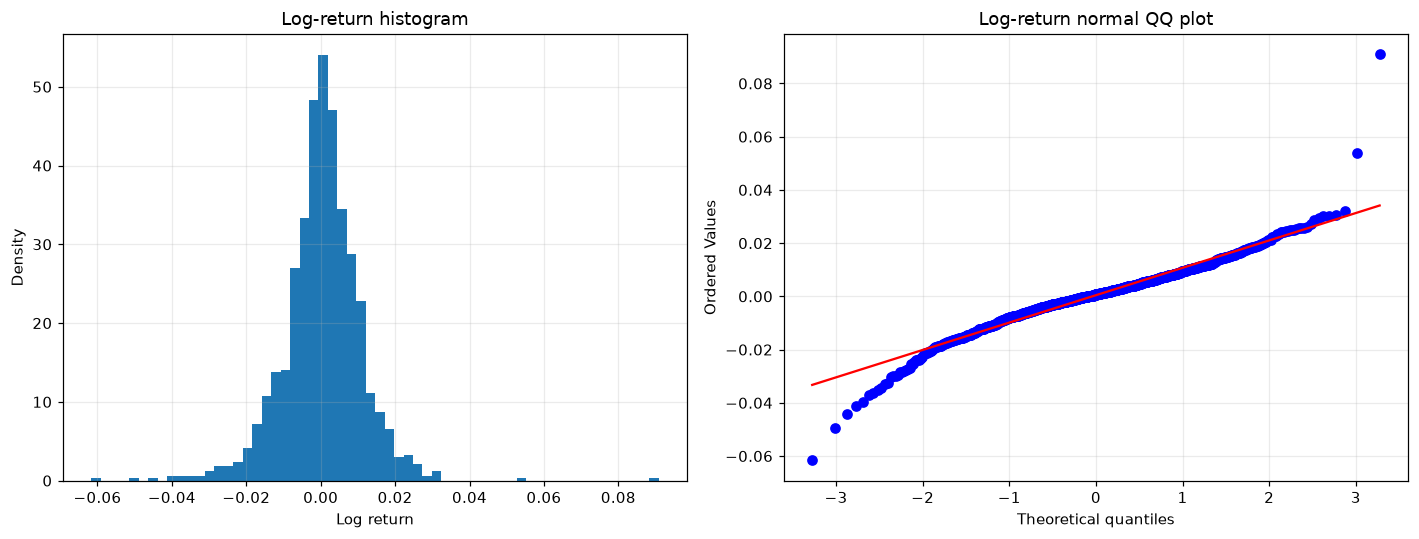

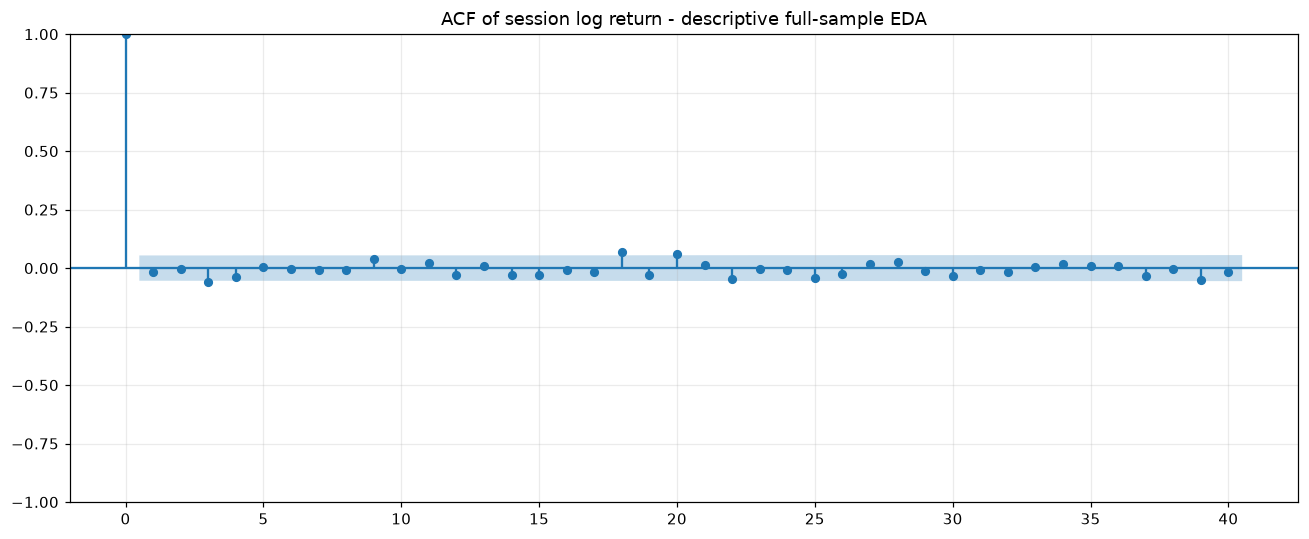

In [4]:
fig, ax = plt.subplots(figsize=(13,5))
ax.plot(df.index,df['Price'])
ax.set(title='S&P 500 closing index - descriptive full sample',ylabel='Index points',xlabel='Session date')
save_figure(fig,'01_raw_index.png')
fig, ax = plt.subplots()
ax.plot(log_ret,linewidth=0.7)
ax.set(title='Session log return',ylabel='Log return',xlabel='Session date')
save_figure(fig,'02_log_return.png')
fig, axes = plt.subplots(1,2,figsize=(13,5))
axes[0].hist(log_ret.dropna(),bins=60,density=True)
axes[0].set(title='Log-return histogram',xlabel='Log return',ylabel='Density')
stats.probplot(log_ret.dropna(),dist='norm',plot=axes[1])
axes[1].set_title('Log-return normal QQ plot')
save_figure(fig,'03_return_distribution.png')
fig, ax = plt.subplots()
plot_acf(log_ret.dropna(),lags=40,ax=ax)
ax.set_title('ACF of session log return - descriptive full-sample EDA')
save_figure(fig,'04_acf_log_return.png')

### Descriptive Statistics

Price and observed-step log return, reported separately for the full sample,
the first 80% (Train), and the final 20% (Test), using the notebook's raw
chronological split before scaling or windowing. Columns identify each sample;
rows give units, dates, Count, Mean, SD, Min, Q1, Median, Q3, Max, Skewness,
and Excess kurtosis.

SD uses `ddof=1`; skewness and excess kurtosis use pandas' bias-corrected
estimators (normal-distribution excess kurtosis = 0). Log returns are natural-log
changes, not percentages, across successive observed dates. The first full-sample
return is undefined and excluded. Returns belong to their ending date, so the
first Test return uses the last Train price. Calendar gaps are not filled.
Full-sample and Test statistics are descriptive reporting only, not inputs to
model selection or fitting. The tables below were calculated from the supplied
source data without rerunning model training.


In [ ]:
# Descriptive reporting only; this cell does not fit or configure a model.
def _make_descriptive_statistics(price, train_ratio):
    assert price.index.is_monotonic_increasing and price.index.is_unique
    assert price.notna().all() and np.isfinite(price).all() and price.gt(0).all()
    split = int(train_ratio * len(price))
    assert 0 < split < len(price)
    # Assign returns to their ending date; retain the Train-to-Test boundary return.
    log_return = np.log(price).diff()
    rows = []
    for variable, series, unit in [('Price', price, 'index points'),
                                    ('Log return', log_return, 'natural log; not percent')]:
        for sample, start, end in [('Full sample', 0, len(price)),
                                    ('Train', 0, split), ('Test', split, len(price))]:
            values = series.iloc[start:end].dropna()
            summary = values.describe(percentiles=[0.25, 0.5, 0.75])
            rows.append({'Variable': variable, 'Sample': sample, 'Unit': unit,
                'Start': str(values.index[0].date()), 'End': str(values.index[-1].date()),
                'Count': int(summary['count']), 'Mean': summary['mean'],
                'SD': summary['std'], 'Min': summary['min'], 'Q1': summary['25%'],
                'Median': summary['50%'], 'Q3': summary['75%'], 'Max': summary['max'],
                'Skewness': values.skew(), 'Excess kurtosis': values.kurt()})
    return pd.DataFrame(rows)

descriptive_statistics = _make_descriptive_statistics(df['Price'], TRAIN_RATIO)
del _make_descriptive_statistics
for _descriptive_variable in ['Price', 'Log return']:
    print(_descriptive_variable)
    display(descriptive_statistics.loc[
        descriptive_statistics['Variable'].eq(_descriptive_variable)
    ].drop(columns='Variable').set_index('Sample').T)
del _descriptive_variable


Price


Sample,Full sample,Train,Test
Unit,index points,index points,index points
Start,2021-07-01,2021-07-01,2025-09-08
End,2026-09-23,2025-09-05,2026-09-23
Count,1313,1050,263
Mean,5266.721813,4812.506895,7080.127376
SD,1151.885882,768.299998,391.319242
Min,3577.03,3577.03,6343.72
Q1,4328.87,4179.7775,6773.155
Median,4975.51,4538.295,6929.94
Q3,6074.08,5501.4375,7465.24


Log return


Sample,Full sample,Train,Test
Unit,natural log; not percent,natural log; not percent,natural log; not percent
Start,2021-07-02,2021-07-02,2025-09-08
End,2026-09-23,2025-09-05,2026-09-23
Count,1312,1049,263
Mean,0.000441,0.000387,0.000658
SD,0.010572,0.011119,0.00804
Min,-0.061609,-0.061609,-0.027486
Q1,-0.00472,-0.00506,-0.003815
Median,0.000731,0.000721,0.000759
Q3,0.006177,0.006369,0.005774


## Step 4 - Chronological Split BEFORE Scaling and Windowing


,split,start_date,end_date,n_sessions,price_min,price_max,price_mean,log_ret_n,log_ret_mean,log_ret_std
0,Train,2021-07-01,2025-09-05,1050,3577.03,6502.08,4812.506895,1049,0.000387,0.011119
1,Test,2025-09-08,2026-09-23,263,6343.72,7798.99,7080.127376,263,0.000658,0.008040


Return SD above uses ddof=1; StandardScaler below uses population SD (ddof=0).


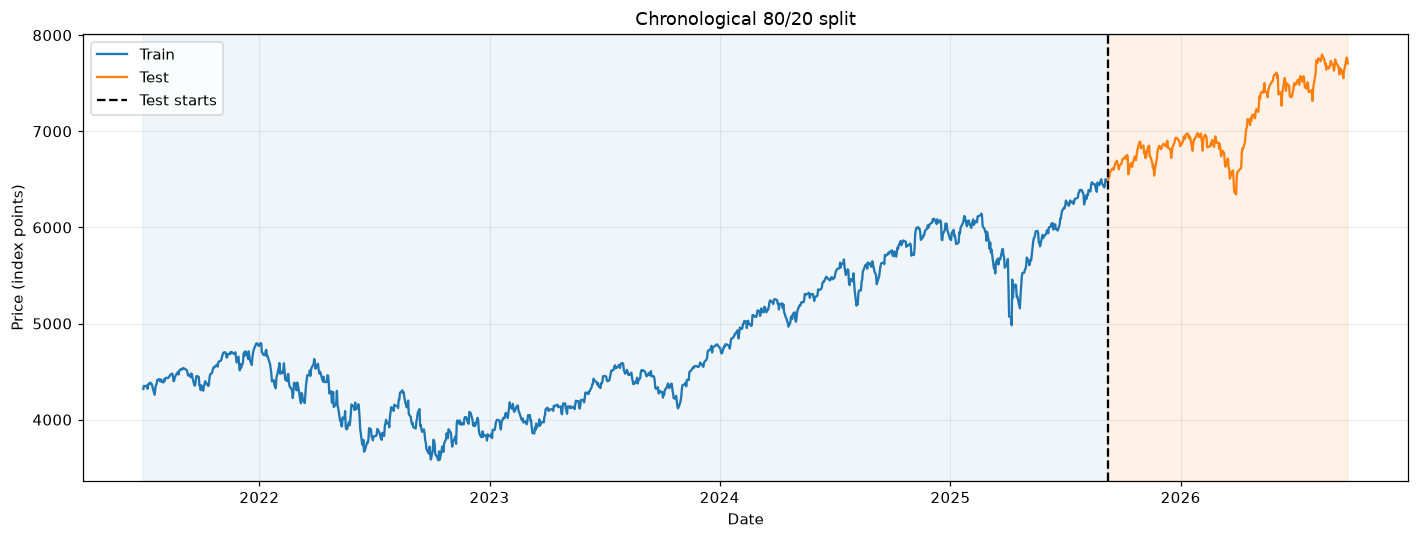

In [5]:
n = len(df)
n_train = int(TRAIN_RATIO * n)
n_test = n - n_train
TRAIN_END_IDX = n_train - 1
assert n_train-LOOKBACK-MAX_H > 0 and n_test >= MAX_H
assert df.index[TRAIN_END_IDX] < df.index[n_train]
train_ret = log_ret.iloc[1:n_train].copy()
split_rows = []
for name, start, end in [('Train', 0, n_train), ('Test', n_train, n)]:
    prices = df['Price'].iloc[start:end]
    returns = log_ret.iloc[start:end].dropna()
    split_rows.append(dict(split=name, start_date=prices.index[0], end_date=prices.index[-1],
        n_sessions=len(prices), price_min=prices.min(), price_max=prices.max(), price_mean=prices.mean(),
        log_ret_n=len(returns), log_ret_mean=returns.mean(), log_ret_std=returns.std(ddof=1)))
split_summary = pd.DataFrame(split_rows)
save_table(split_summary, 'split_summary.csv')
display(split_summary)
print('Return SD above uses ddof=1; StandardScaler below uses population SD (ddof=0).')
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(df['Price'].iloc[:n_train], label='Train', color='tab:blue')
ax.plot(df['Price'].iloc[n_train:], label='Test', color='tab:orange')
ax.axvspan(df.index[0], df.index[n_train], alpha=0.07, color='tab:blue')
ax.axvspan(df.index[n_train], df.index[-1], alpha=0.10, color='tab:orange')
ax.axvline(df.index[n_train], color='black', linestyle='--', label='Test starts')
ax.set(title='Chronological 80/20 split', ylabel='Price (index points)', xlabel='Date')
ax.legend()
save_figure(fig, '05_train_test_split.png')

## Step 5 - Scaling (fit on Train returns only)

Fit the StandardScaler only on valid return indices 1..n_train-1. The first missing return is structural. Transform Test inputs with the frozen Train mean/SD; Test never contributes to fitting.

In [6]:
scaler_fit_indices = np.arange(1, n_train)
assert scaler_fit_indices.max() <= TRAIN_END_IDX
scaler = StandardScaler()
scaler.fit(train_ret.to_numpy().reshape(-1, 1))
assert int(scaler.n_samples_seen_) == len(scaler_fit_indices)
assert train_ret.index.max() <= df.index[TRAIN_END_IDX]
scaler_mean = float(scaler.mean_[0])
scaler_std = float(scaler.scale_[0])
assert scaler_std > 0
np.testing.assert_allclose(scaler_mean, train_ret.mean(), atol=1e-12)
np.testing.assert_allclose(scaler_std, train_ret.std(ddof=0), atol=1e-12)
z = np.full(n, np.nan, dtype=np.float64)
z[1:] = scaler.transform(log_ret.iloc[1:].to_numpy().reshape(-1, 1)).ravel()
assert np.isnan(z[0]) and np.isfinite(z[1:]).all()
scaler_params = dict(mean=scaler_mean, std=scaler_std, ddof=0,
    fit_first_index=int(scaler_fit_indices.min()), fit_last_index=int(scaler_fit_indices.max()),
    n_samples=int(scaler.n_samples_seen_), fit_end_date=str(train_ret.index[-1].date()))
print('Frozen scaler:', scaler_params)
frozen_scaler_hash = scaler_digest(scaler)
save_table(pd.DataFrame([scaler_params]),"scaler_provenance.csv")

Frozen scaler: {'mean': 0.00038676807551764895, 'std': 0.011113592303050979, 'ddof': 0, 'fit_first_index': 1, 'fit_last_index': 1049, 'n_samples': 1049, 'fit_end_date': '2025-09-05'}


## Step 6 - MIMO Train windows

X contains LOOKBACK=60 scaled session returns through origin t; y contains the next MAX_H=30 individual scaled returns. All inputs and targets stay inside Train; no validation windows. Window counts are computed from this dataset.

In [7]:
train_origins = np.arange(LOOKBACK, TRAIN_END_IDX - MAX_H + 1)
train_input_indices = train_origins[:, None] - np.arange(LOOKBACK-1, -1, -1)[None, :]
train_target_indices = train_origins[:, None] + np.arange(1, MAX_H+1)[None, :]
assert train_input_indices.min() >= 1
assert train_input_indices.max() <= TRAIN_END_IDX
assert train_target_indices.max() <= TRAIN_END_IDX
assert (train_input_indices < n_train).all() and (train_target_indices < n_train).all()
X_train = z[train_input_indices][..., None].astype(np.float32)
y_train = z[train_target_indices].astype(np.float32)
assert X_train.shape == (len(train_origins), LOOKBACK, 1)
assert y_train.shape == (len(train_origins), MAX_H)
assert len(train_origins) == TRAIN_END_IDX - MAX_H - LOOKBACK + 1
assert np.isfinite(X_train).all() and np.isfinite(y_train).all()
window_audit = pd.DataFrame(dict(origin_idx=train_origins, origin_date=df.index[train_origins],
    input_start_idx=train_input_indices[:, 0], input_end_idx=train_input_indices[:, -1],
    target_start_idx=train_target_indices[:, 0], target_end_idx=train_target_indices[:, -1]))
save_table(window_audit, 'training_window_audit.csv')
print('Training samples:', len(train_origins), 'X:', X_train.shape, 'y:', y_train.shape)
display(window_audit.iloc[[0,-1]])

Training samples: 960 X: (960, 60, 1) y: (960, 30)


,origin_idx,origin_date,input_start_idx,input_end_idx,target_start_idx,target_end_idx
0,60,2021-09-27,1,60,61,90
959,1019,2025-07-24,960,1019,1020,1049


### Step 6.1 - Verify patch geometry before model construction
This checks only replication padding and patch shapes. It does not define or train the encoder. The input remains chronological within each window.

In [8]:
assert PADDING_PATCH == 'end'
patch_count = (LOOKBACK+STRIDE-PATCH_LEN)//STRIDE+1
probe = torch.from_numpy(X_train[:2]).transpose(1,2)
padded = nn.ReplicationPad1d((0,STRIDE))(probe)
patches = padded.unfold(dimension=-1,size=PATCH_LEN,step=STRIDE)
assert padded.shape == (2,1,LOOKBACK+STRIDE)
assert patches.shape == (2,1,patch_count,PATCH_LEN)
assert patch_count > 0 and LOOKBACK+STRIDE >= PATCH_LEN
assert torch.equal(padded[:,:,-STRIDE:],probe[:,:,-1:].expand(-1,-1,STRIDE))
print('CPU:',DEVICE,'; padded input:',tuple(padded.shape),'; patches:',tuple(patches.shape))
print('Preparation complete. Patch geometry verified before model training.')

CPU: cpu ; padded input: (2, 1, 68) ; patches: (2, 1, 7, 16)
Preparation complete. Patch geometry verified before model training.


## Step 7 - PatchTST architecture, implemented in PyTorch
Univariate channel-independent patch encoder: non-affine RevIN -> end replication padding -> 7 x 16 patches -> linear embedding + learned positions -> three encoder blocks with four-head attention, BatchNorm and GELU -> flatten -> linear 30-session head -> RevIN denormalize.

The encoder accumulates attention logits across blocks (residual attention), following the official backbone. BatchNorm has train-only running statistics and is frozen in eval mode. RevIN uses only the current input window's detached mean/std; it never computes statistics from future targets. `FC_DROPOUT` is a recorded official argument for the pretraining head and is not an extra dropout in the supervised flatten head. `HEAD_DROPOUT=0` makes the specified head ordering equivalent to the official supervised head.

In [9]:
class PatchEncoderBlock(nn.Module):
    def __init__(self):
        super().__init__()
        self.heads = N_HEADS
        self.head_dim = D_MODEL//N_HEADS
        self.qkv = nn.Linear(D_MODEL,3*D_MODEL)
        self.project = nn.Sequential(nn.Linear(D_MODEL,D_MODEL),nn.Dropout(DROPOUT))
        self.attention_residual = nn.Dropout(DROPOUT)
        self.bn_attention = nn.BatchNorm1d(D_MODEL)
        self.ff = nn.Sequential(nn.Linear(D_MODEL,D_FF),nn.GELU(),
            nn.Dropout(DROPOUT),nn.Linear(D_FF,D_MODEL))
        self.ff_residual = nn.Dropout(DROPOUT)
        self.bn_ff = nn.BatchNorm1d(D_MODEL)

    def forward(self,x,previous_scores=None):
        batch,patches,_ = x.shape
        q,k,v = self.qkv(x).chunk(3,dim=-1)
        def heads(t): return t.reshape(batch,patches,self.heads,self.head_dim).transpose(1,2)
        q,k,v = heads(q),heads(k),heads(v)
        scores = (q@k.transpose(-1,-2)) * (self.head_dim**-0.5)
        if previous_scores is not None: scores = scores+previous_scores
        attended = (scores.softmax(dim=-1)@v).transpose(1,2).reshape(batch,patches,D_MODEL)
        x = self.bn_attention((x+self.attention_residual(self.project(attended))).transpose(1,2)).transpose(1,2)
        x = self.bn_ff((x+self.ff_residual(self.ff(x))).transpose(1,2)).transpose(1,2)
        return x,scores

class PatchTST(nn.Module):
    def __init__(self):
        super().__init__()
        assert D_MODEL%N_HEADS==0 and PADDING_PATCH=='end'
        self.patch_count = (LOOKBACK+STRIDE-PATCH_LEN)//STRIDE+1
        self.pad = nn.ReplicationPad1d((0,STRIDE))
        self.embedding = nn.Linear(PATCH_LEN,D_MODEL)
        self.position = nn.Parameter(torch.empty(self.patch_count,D_MODEL))
        nn.init.uniform_(self.position,-0.02,0.02)
        self.embedding_dropout = nn.Dropout(DROPOUT)
        self.encoder = nn.ModuleList([PatchEncoderBlock() for _ in range(N_LAYERS)])
        self.head = nn.Sequential(nn.Flatten(start_dim=1),nn.Dropout(HEAD_DROPOUT),
            nn.Linear(self.patch_count*D_MODEL,MAX_H))

    def forward(self,x):
        assert x.ndim==3 and x.shape[1:]==(LOOKBACK,1)
        mean = x.mean(dim=1,keepdim=True).detach()
        std = torch.sqrt(x.var(dim=1,keepdim=True,unbiased=False)+1e-5).detach()
        normalized = (x-mean)/std if REVIN else x
        patches = self.pad(normalized.transpose(1,2)).unfold(-1,PATCH_LEN,STRIDE).squeeze(1)
        assert patches.shape[1:]==(self.patch_count,PATCH_LEN)
        encoded = self.embedding_dropout(self.embedding(patches)+self.position)
        scores = None
        for block in self.encoder: encoded,scores = block(encoded,scores)
        # Official flattened representation is feature-major: (D_MODEL, patches).
        predicted = self.head(encoded.transpose(1,2))
        if REVIN: predicted = predicted*std[:,0,:]+mean[:,0,:]
        return predicted

def weights_digest(model):
    digest=hashlib.sha256()
    for name,value in sorted(model.state_dict().items()):
        array=value.detach().cpu().contiguous().numpy()
        digest.update(name.encode()); digest.update(str(array.dtype).encode())
        digest.update(str(array.shape).encode()); digest.update(array.tobytes())
    return digest.hexdigest()

set_seed(SEEDS[0])
architecture_model=PatchTST().to(DEVICE)
parameter_count=sum(p.numel() for p in architecture_model.parameters())
architecture_model.eval()
with torch.no_grad():
    output_probe=architecture_model(torch.from_numpy(X_train[:2]).to(DEVICE))
assert output_probe.shape==(2,MAX_H) and torch.isfinite(output_probe).all()
architecture_text=str(architecture_model)+f'\nTotal trainable parameters: {parameter_count}\nTraining samples: {len(X_train)}\n'
print(architecture_text)
del architecture_model

PatchTST(
  (pad): ReplicationPad1d((0, 8))
  (embedding): Linear(in_features=16, out_features=16, bias=True)
  (embedding_dropout): Dropout(p=0.3, inplace=False)
  (encoder): ModuleList(
    (0-2): 3 x PatchEncoderBlock(
      (qkv): Linear(in_features=16, out_features=48, bias=True)
      (project): Sequential(
        (0): Linear(in_features=16, out_features=16, bias=True)
        (1): Dropout(p=0.3, inplace=False)
      )
      (attention_residual): Dropout(p=0.3, inplace=False)
      (bn_attention): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (ff): Sequential(
        (0): Linear(in_features=16, out_features=128, bias=True)
        (1): GELU(approximate='none')
        (2): Dropout(p=0.3, inplace=False)
        (3): Linear(in_features=128, out_features=16, bias=True)
      )
      (ff_residual): Dropout(p=0.3, inplace=False)
      (bn_ff): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)

## Step 8 - Fixed-budget training once per predefined seed
Adam with MSE, 100 epochs, fixed OneCycleLR schedule; only training loss is calculated. DataLoader shuffles complete training samples with a seeded generator; temporal order inside each window is preserved. Final-epoch weights are saved for every seed without selecting a checkpoint or seed by Test performance.

Training seed=0: 100 fixed epochs


  seed=0 epoch=20: Train MSE=1.358516


  seed=0 epoch=40: Train MSE=1.249214


  seed=0 epoch=60: Train MSE=1.185570


  seed=0 epoch=80: Train MSE=1.159088


...

  seed=4 epoch=40: Train MSE=1.236739


  seed=4 epoch=60: Train MSE=1.160053


  seed=4 epoch=80: Train MSE=1.137583


  seed=4 epoch=100: Train MSE=1.132914


Finished seed=4; Train MSE 1.411539 -> 1.132914


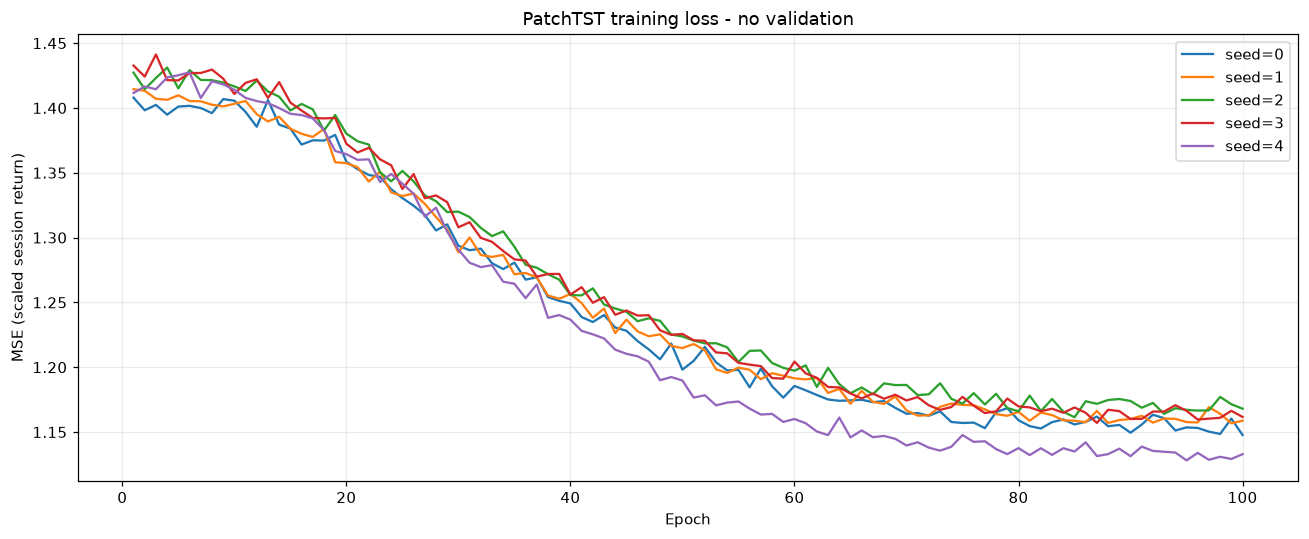

,seed,n_epochs,first_loss,final_loss,loss_reduced,seconds
0,0,100,1.407945,1.147719,True,16.778224
1,1,100,1.414431,1.158776,True,16.962991
2,2,100,1.427233,1.168044,True,16.507846
3,3,100,1.432676,1.161666,True,17.058848
4,4,100,1.411539,1.132914,True,17.349661


In [10]:
models, frozen_weight_hashes, training_rows, training_audit_rows, lr_rows = {}, {}, [], [], []
train_dataset = TensorDataset(torch.from_numpy(X_train),torch.from_numpy(y_train))
for seed in SEEDS:
    set_seed(seed)
    generator = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(train_dataset,batch_size=BATCH_SIZE,shuffle=True,
        generator=generator,num_workers=0,drop_last=False)
    model = PatchTST().to(DEVICE)
    optimizer = Adam(model.parameters(),lr=LR)
    scheduler = OneCycleLR(optimizer,max_lr=LR,pct_start=PCT_START,
        epochs=EPOCHS,steps_per_epoch=len(train_loader))
    loss_fn = nn.MSELoss()
    epoch_losses=[]
    started=time.perf_counter()
    print(f'Training seed={seed}: {EPOCHS} fixed epochs',flush=True)
    for epoch in range(1,EPOCHS+1):
        model.train()
        total_loss=0.0
        total_samples=0
        for inputs,targets in train_loader:
            inputs,targets=inputs.to(DEVICE),targets.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            predicted=model(inputs)
            loss=loss_fn(predicted,targets)
            assert torch.isfinite(loss), f'Non-finite Train loss: seed={seed}, epoch={epoch}'
            loss.backward()
            lr_rows.append(dict(seed=seed,step=len(lr_rows)+1,learning_rate=optimizer.param_groups[0]['lr']))
            optimizer.step()
            scheduler.step()
            total_loss+=loss.item()*len(inputs)
            total_samples+=len(inputs)
        epoch_loss=total_loss/total_samples
        epoch_losses.append(epoch_loss)
        training_rows.append(dict(seed=seed,epoch=epoch,loss=epoch_loss))
        if epoch%20==0: print(f'  seed={seed} epoch={epoch}: Train MSE={epoch_loss:.6f}',flush=True)
    model.eval()
    models[seed]=model
    frozen_weight_hashes[seed]=weights_digest(model)
    training_audit_rows.append(dict(seed=seed,n_epochs=len(epoch_losses),
        first_loss=epoch_losses[0],final_loss=epoch_losses[-1],
        loss_reduced=epoch_losses[-1]<epoch_losses[0],seconds=time.perf_counter()-started))
    print(f'Finished seed={seed}; Train MSE {epoch_losses[0]:.6f} -> {epoch_losses[-1]:.6f}',flush=True)
training_loss=pd.DataFrame(training_rows)
training_audit=pd.DataFrame(training_audit_rows)
save_table(training_loss,'training_loss.csv')
save_table(training_audit,'training_audit.csv')
save_table(pd.DataFrame(lr_rows),'learning_rate_schedule.csv')
assert len(training_loss)==len(SEEDS)*EPOCHS
fig,ax=plt.subplots()
for seed in SEEDS:
    group=training_loss.loc[training_loss.seed.eq(seed)]
    ax.plot(group.epoch,group.loss,label=f'seed={seed}')
ax.set(title='PatchTST training loss - no validation',xlabel='Epoch',ylabel='MSE (scaled session return)')
ax.legend(); save_figure(fig,'06_training_loss.png')
display(training_audit)

## Step 9 - Rolling-origin forecasting with fixed weights
All all eligible Test origins plus the latest observed origin are predicted in one batch per seed in eval/no_grad mode. No future observations enter an origin's input. Ensemble averaging occurs in session-return space before cumulative sums and exponentiation; it is not an average of forecast prices. BatchNorm running buffers and learned parameters are hashed before and after inference.

In [11]:
assert scaler_digest(scaler)==frozen_scaler_hash
test_origins = np.arange(TRAIN_END_IDX, n-1)
inference_origins = np.r_[test_origins, n-1]
inference_input_indices = inference_origins[:, None] - np.arange(LOOKBACK-1, -1, -1)[None, :]
assert len(test_origins) == n_test
assert inference_input_indices.min() >= 1
assert (inference_input_indices <= inference_origins[:, None]).all()
X_inference = z[inference_input_indices][..., None].astype(np.float32)
assert X_inference.shape == (n_test+1, LOOKBACK, 1) and np.isfinite(X_inference).all()
return_predictions = []
weight_audit_rows = []
for seed in SEEDS:
    assert weights_digest(models[seed]) == frozen_weight_hashes[seed]
    models[seed].eval()
    with torch.no_grad():
        predicted_z = models[seed](torch.from_numpy(X_inference).to(DEVICE)).cpu().numpy().astype(np.float64)
    assert predicted_z.shape == (len(inference_origins), MAX_H)
    predicted_returns = predicted_z * scaler_std + scaler_mean
    np.testing.assert_allclose(predicted_returns,
        scaler.inverse_transform(predicted_z.reshape(-1,1)).reshape(predicted_z.shape), atol=1e-12)
    return_predictions.append(predicted_returns)
    after = weights_digest(models[seed])
    assert after == frozen_weight_hashes[seed], 'Weights changed during inference'
    weight_audit_rows.append(dict(seed=seed, train_hash=frozen_weight_hashes[seed],
        after_predict_hash=after, unchanged=after == frozen_weight_hashes[seed]))
return_predictions = np.stack(return_predictions, axis=0)
return_predictions_ens = return_predictions.mean(axis=0)
origin_prices = df['Price'].iloc[inference_origins].to_numpy()
seed_prices = origin_prices[None, :, None] * np.exp(np.cumsum(return_predictions, axis=2))
ensemble_prices = origin_prices[:, None] * np.exp(np.cumsum(return_predictions_ens, axis=1))
forecast_rows = []
for h in HORIZONS:
    eligible = np.flatnonzero(test_origins + h < n)
    for pos in eligible:
        origin = int(test_origins[pos])
        target = origin + h
        row = dict(origin_date=df.index[origin], h=h, target_date=df.index[target],
            price_origin=df['Price'].iloc[origin], actual=df['Price'].iloc[target],
            patchtst_fc_ens=ensemble_prices[pos, h-1])
        row.update({f'patchtst_fc_seed{seed}': seed_prices[k, pos, h-1] for k,seed in enumerate(SEEDS)})
        forecast_rows.append(row)
forecasts = pd.DataFrame(forecast_rows).sort_values(['h','target_date']).reset_index(drop=True)
assert forecasts.groupby('h').size().to_dict() == {h:n_test-h+1 for h in HORIZONS}
assert not forecasts.duplicated(['origin_date','h']).any()
assert (forecasts['target_date'] >= df.index[n_train]).all()
assert (df.index.get_indexer(forecasts['target_date'])-df.index.get_indexer(forecasts['origin_date'])==forecasts['h'].to_numpy()).all()
save_table(forecasts, 'forecasts_long.csv')
weight_audit = pd.DataFrame(weight_audit_rows)
save_table(weight_audit, 'weights_fixed_audit.csv')
display(forecasts.groupby('h').size().rename('n_points').to_frame())
assert scaler_digest(scaler)==frozen_scaler_hash

,n_points
h,
1,263
3,261
5,259
7,257
14,250
21,243
30,234


### Step 9.1 - Historical Test forecast tables by horizon
`origin_date` is the last known observation. `target_date = origin_date + h` lies inside Test; `actual` is used only to evaluate the forecast. All rows are exported, with scrollable notebook displays.

In [12]:
for h in HORIZONS:
    horizon_forecasts = forecasts.loc[forecasts['h'].eq(h)].copy()
    save_table(horizon_forecasts, f'forecasts_h{h}.csv')
    display(Markdown(f'**h = {h} trading sessions: {len(horizon_forecasts)} test forecasts**'))
    show_scroll_table(horizon_forecasts)

**h = 1 trading sessions: 263 test forecasts**

origin_date,h,target_date,price_origin,actual,patchtst_fc_ens,patchtst_fc_seed0,patchtst_fc_seed1,patchtst_fc_seed2,patchtst_fc_seed3,patchtst_fc_seed4
2025-09-05,1,2025-09-08,"6,481.5000","6,495.1500","6,488.4698","6,481.3609","6,477.4438","6,505.6574","6,487.8890","6,490.0343"
2025-09-08,1,2025-09-09,"6,495.1500","6,512.6100","6,505.0561","6,498.3867","6,511.7226","6,515.3215","6,492.1587","6,507.7193"
2025-09-09,1,2025-09-10,"6,512.6100","6,532.0400","6,515.2643","6,512.2114","6,500.7895","6,513.9122","6,524.6947","6,524.7447"
2025-09-10,1,2025-09-11,"6,532.0400","6,587.4700","6,541.1039","6,527.4158","6,551.5255","6,540.0286","6,543.2321","6,543.3409"
2025-09-11,1,2025-09-12,"6,587.4700","6,584.2900","6,596.0914","6,604.7651","6,589.2521","6,594.7006","6,596.1987","6,595.5497"
2025-09-12,1,2025-09-15,"6,584.2900","6,615.2800","6,590.9815","6,596.8804","6,586.0666","6,588.8843","6,590.2782","6,592.8030"
2025-09-15,1,2025-09-16,"6,615.2800","6,606.7600","6,620.7999","6,623.6421","6,622.6824","6,610.0961","6,620.0718","6,627.5199"
2025-09-16,1,2025-09-17,"6,606.7600","6,600.3500","6,616.9919","6,621.5393","6,614.5082","6,624.7585","6,613.3291","6,610.8350"
2025-09-17,1,2025-09-18,"6,600.3500","6,631.9600","6,611.7722","6,615.1911","6,602.2993","6,606.9752","6,624.1628","6,610.2537"
2025-09-18,1,2025-09-19,"6,631.9600","6,664.3600","6,643.7679","6,643.4054","6,657.4961","6,642.1696","6,640.7574","6,635.0317"


**h = 3 trading sessions: 261 test forecasts**

origin_date,h,target_date,price_origin,actual,patchtst_fc_ens,patchtst_fc_seed0,patchtst_fc_seed1,patchtst_fc_seed2,patchtst_fc_seed3,patchtst_fc_seed4
2025-09-05,3,2025-09-10,"6,481.5000","6,532.0400","6,509.4979","6,507.7881","6,489.3139","6,529.6158","6,507.2349","6,513.6013"
2025-09-08,3,2025-09-11,"6,495.1500","6,587.4700","6,531.8994","6,524.1425","6,537.5149","6,540.8506","6,518.6199","6,538.3987"
2025-09-09,3,2025-09-12,"6,512.6100","6,584.2900","6,535.7070","6,536.3860","6,518.9794","6,524.6330","6,545.4697","6,553.1283"
2025-09-10,3,2025-09-15,"6,532.0400","6,615.2800","6,558.1503","6,552.8091","6,543.5737","6,571.9888","6,556.5375","6,565.8803"
2025-09-11,3,2025-09-16,"6,587.4700","6,606.7600","6,614.8713","6,611.3354","6,624.5200","6,612.2951","6,621.8392","6,604.3871"
2025-09-12,3,2025-09-17,"6,584.2900","6,600.3500","6,605.5891","6,603.1769","6,595.9573","6,592.9966","6,627.5314","6,608.3399"
2025-09-15,3,2025-09-18,"6,615.2800","6,631.9600","6,637.3038","6,645.4585","6,631.8082","6,626.9846","6,640.6227","6,641.6625"
2025-09-16,3,2025-09-19,"6,606.7600","6,664.3600","6,639.4499","6,634.0330","6,624.6185","6,663.0951","6,634.6400","6,640.9258"
2025-09-17,3,2025-09-22,"6,600.3500","6,693.7500","6,627.8424","6,620.7568","6,615.4202","6,642.0875","6,637.7268","6,623.2606"
2025-09-18,3,2025-09-23,"6,631.9600","6,656.9200","6,672.2941","6,668.6677","6,683.7193","6,664.1662","6,667.1124","6,677.8249"


**h = 5 trading sessions: 259 test forecasts**

...

origin_date,h,target_date,price_origin,actual,patchtst_fc_ens,patchtst_fc_seed0,patchtst_fc_seed1,patchtst_fc_seed2,patchtst_fc_seed3,patchtst_fc_seed4
2025-09-05,14,2025-09-25,"6,481.5000","6,604.7200","6,588.3504","6,636.9724","6,588.2070","6,573.7861","6,573.9620","6,569.0633"
2025-09-08,14,2025-09-26,"6,495.1500","6,643.7000","6,645.7493","6,670.6068","6,639.5795","6,664.7091","6,621.6001","6,632.3846"
2025-09-09,14,2025-09-29,"6,512.6100","6,661.2100","6,610.7318","6,619.7768","6,578.0554","6,611.1756","6,621.3314","6,623.4278"
2025-09-10,14,2025-09-30,"6,532.0400","6,688.4600","6,664.3556","6,665.0049","6,632.2988","6,702.8689","6,652.8242","6,668.9810"
2025-09-11,14,2025-10-01,"6,587.4700","6,711.2000","6,727.6804","6,741.6664","6,756.9248","6,692.8122","6,722.4111","6,724.7585"
2025-09-12,14,2025-10-02,"6,584.2900","6,715.3500","6,732.1064","6,713.5108","6,712.1072","6,724.5558","6,784.6023","6,726.0217"
2025-09-15,14,2025-10-03,"6,615.2800","6,715.7900","6,758.2922","6,763.5314","6,713.7003","6,756.4661","6,779.5318","6,778.4448"
2025-09-16,14,2025-10-06,"6,606.7600","6,740.2800","6,782.8283","6,757.3256","6,737.6100","6,848.6510","6,799.8076","6,771.2951"
2025-09-17,14,2025-10-07,"6,600.3500","6,714.5900","6,746.5979","6,741.0118","6,739.3254","6,765.2740","6,759.1684","6,728.2786"
2025-09-18,14,2025-10-08,"6,631.9600","6,753.7200","6,795.3057","6,768.2167","6,834.4879","6,781.9144","6,823.3612","6,768.8377"


**h = 21 trading sessions: 243 test forecasts**

origin_date,h,target_date,price_origin,actual,patchtst_fc_ens,patchtst_fc_seed0,patchtst_fc_seed1,patchtst_fc_seed2,patchtst_fc_seed3,patchtst_fc_seed4
2025-09-05,21,2025-10-06,"6,481.5000","6,740.2800","6,651.4849","6,708.1591","6,625.5519","6,664.0459","6,606.9922","6,653.1278"
2025-09-08,21,2025-10-07,"6,495.1500","6,714.5900","6,718.2926","6,768.4349","6,738.0952","6,691.6452","6,725.4923","6,668.2551"
2025-09-09,21,2025-10-08,"6,512.6100","6,753.7200","6,681.1098","6,679.8254","6,651.5705","6,657.3261","6,708.8107","6,708.2367"
2025-09-10,21,2025-10-09,"6,532.0400","6,735.1100","6,737.7520","6,739.7892","6,688.8461","6,781.9918","6,748.2848","6,730.1839"
2025-09-11,21,2025-10-10,"6,587.4700","6,552.5100","6,800.8796","6,817.1457","6,825.1657","6,746.7616","6,801.1605","6,814.4571"
2025-09-12,21,2025-10-13,"6,584.2900","6,654.7200","6,799.0603","6,751.0339","6,791.1509","6,812.2769","6,845.3940","6,795.7916"
2025-09-15,21,2025-10-14,"6,615.2800","6,644.3100","6,841.0524","6,849.2236","6,751.4695","6,855.1508","6,877.9793","6,872.2200"
2025-09-16,21,2025-10-15,"6,606.7600","6,671.0600","6,849.1389","6,801.7113","6,834.3897","6,897.8941","6,852.6965","6,859.3651"
2025-09-17,21,2025-10-16,"6,600.3500","6,629.0700","6,803.1022","6,797.9478","6,808.4324","6,821.0793","6,797.5015","6,790.5917"
2025-09-18,21,2025-10-17,"6,631.9600","6,664.0100","6,851.7271","6,830.1802","6,881.6361","6,843.0067","6,857.9792","6,845.9431"


**h = 30 trading sessions: 234 test forecasts**

origin_date,h,target_date,price_origin,actual,patchtst_fc_ens,patchtst_fc_seed0,patchtst_fc_seed1,patchtst_fc_seed2,patchtst_fc_seed3,patchtst_fc_seed4
2025-09-05,30,2025-10-17,"6,481.5000","6,664.0100","6,718.3512","6,767.1486","6,695.8616","6,695.4187","6,684.0383","6,749.7031"
2025-09-08,30,2025-10-20,"6,495.1500","6,735.1300","6,780.5378","6,829.3700","6,768.1521","6,782.3138","6,773.9692","6,749.1464"
2025-09-09,30,2025-10-21,"6,512.6100","6,735.3500","6,752.4918","6,762.4758","6,736.1879","6,699.0842","6,754.2818","6,810.9202"
2025-09-10,30,2025-10-22,"6,532.0400","6,699.4000","6,831.0995","6,852.5938","6,795.9054","6,840.6494","6,850.8745","6,815.6518"
2025-09-11,30,2025-10-23,"6,587.4700","6,738.4400","6,886.2803","6,893.5133","6,944.4597","6,829.8950","6,864.2899","6,899.7723"
2025-09-12,30,2025-10-24,"6,584.2900","6,791.6900","6,895.7153","6,860.8229","6,855.9137","6,877.4114","6,976.2362","6,908.8996"
2025-09-15,30,2025-10-27,"6,615.2800","6,875.1600","6,962.0016","6,960.6313","6,904.4814","6,962.8147","7,008.7523","6,973.7336"
2025-09-16,30,2025-10-28,"6,606.7600","6,890.8900","6,960.8805","6,888.3271","6,932.3491","7,055.5778","6,955.7500","6,973.4893"
2025-09-17,30,2025-10-29,"6,600.3500","6,890.5900","6,918.1371","6,905.2258","6,935.8548","6,945.9502","6,931.6691","6,872.2423"
2025-09-18,30,2025-10-30,"6,631.9600","6,822.3400","6,936.0336","6,911.1806","6,976.8379","6,910.1986","6,934.3225","6,947.8513"


### Step 9.2 - Future forecasts from the latest observation
All horizons share the final observed origin, using the fixed original Train weights. Future target dates have no actual values or error metrics yet. Target dates use the declared NYSE session calendar.

In [13]:
assert scaler_digest(scaler)==frozen_scaler_hash
future_rows = []
latest_origin = df.index[-1]
for h in HORIZONS:
    row = dict(origin_date=latest_origin, h=h, target_date=future_dates[h-1],
        price_origin=float(df['Price'].iloc[-1]), patchtst_fc_ens=ensemble_prices[-1,h-1])
    row.update({f'patchtst_fc_seed{seed}': seed_prices[k,-1,h-1] for k,seed in enumerate(SEEDS)})
    future_rows.append(row)
future_forecasts = pd.DataFrame(future_rows)
assert (future_forecasts['target_date'] > df.index[-1]).all()
save_table(future_forecasts, 'future_forecast_by_horizon.csv')
show_scroll_table(future_forecasts)
assert scaler_digest(scaler)==frozen_scaler_hash

origin_date,h,target_date,price_origin,patchtst_fc_ens,patchtst_fc_seed0,patchtst_fc_seed1,patchtst_fc_seed2,patchtst_fc_seed3,patchtst_fc_seed4
2026-09-23,1,2026-09-24,"7,706.0300","7,708.1105","7,722.4068","7,699.9184","7,708.6236","7,684.9345","7,724.7394"
2026-09-23,3,2026-09-28,"7,706.0300","7,709.9494","7,701.1261","7,708.5631","7,734.7618","7,677.4244","7,728.0066"
2026-09-23,5,2026-09-30,"7,706.0300","7,724.7077","7,692.1207","7,719.2821","7,779.5858","7,693.0699","7,739.8246"
2026-09-23,7,2026-10-02,"7,706.0300","7,747.6918","7,710.1075","7,743.8469","7,814.7390","7,695.7687","7,774.5993"
2026-09-23,14,2026-10-13,"7,706.0300","7,792.4504","7,758.8892","7,811.5058","7,912.4727","7,683.3152","7,797.8531"
2026-09-23,21,2026-10-22,"7,706.0300","7,830.2747","7,788.4974","7,870.8284","7,960.4342","7,700.4976","7,833.4903"
2026-09-23,30,2026-11-04,"7,706.0300","7,857.1118","7,804.8171","7,892.0415","8,004.6135","7,732.1929","7,854.5176"


### 9.3 Daily future forecast tables - next 7 and 30 steps

Horizons count NYSE trading sessions and retain the existing holiday calendar.

Uses the existing fixed Train MIMO path, with ensemble and per-seed forecasts. Seed spread is not a calibrated prediction interval.

Both complete tables are embedded below and retained via the existing notebook-only save_table helper.


In [14]:
daily_steps = max(DAILY_FORECAST_WINDOWS)
daily_origin = pd.Timestamp(df.index[-1])
daily_origin_price = float(df['Price'].iloc[-1])
daily_dates = pd.DatetimeIndex(future_dates[:daily_steps])
assert len(daily_dates) == daily_steps
assert daily_dates.is_unique and daily_dates.is_monotonic_increasing
assert (daily_dates > daily_origin).all()
future_forecast_daily = pd.DataFrame(dict(origin_date=daily_origin,
    h=np.arange(1, daily_steps + 1), target_date=daily_dates,
    day_of_week=daily_dates.day_name(), price_origin=daily_origin_price))
# Reuse the full MIMO price path, averaging predicted daily returns before compounding.
assert scaler_digest(scaler) == frozen_scaler_hash
future_forecast_daily['patchtst_fc_ens'] = ensemble_prices[-1, :daily_steps]
for k, seed in enumerate(SEEDS):
    assert weights_digest(models[seed]) == frozen_weight_hashes[seed]
    future_forecast_daily[f'patchtst_fc_seed{seed}'] = seed_prices[k, -1, :daily_steps]
daily_forecast_columns = ['patchtst_fc_ens', *[f'patchtst_fc_seed{seed}' for seed in SEEDS]]
assert len(future_forecast_daily) == daily_steps
assert future_forecast_daily['origin_date'].nunique() == 1
assert future_forecast_daily['h'].tolist() == list(range(1, daily_steps + 1))
assert future_forecast_daily['target_date'].equals(pd.Series(daily_dates, name='target_date'))
values = future_forecast_daily[daily_forecast_columns].to_numpy()
assert np.isfinite(values).all() and (values > 0).all()
np.testing.assert_allclose(future_forecast_daily.set_index('h').loc[HORIZONS, ['patchtst_fc_ens']],
    future_forecasts.set_index('h').loc[HORIZONS, ['patchtst_fc_ens']], rtol=1e-12)
assert (future_forecast_daily.set_index('h').loc[HORIZONS, 'target_date'].to_numpy() ==
        future_forecasts.set_index('h').loc[HORIZONS, 'target_date'].to_numpy()).all()
future_daily_tables = {}
for days in DAILY_FORECAST_WINDOWS:
    table = future_forecast_daily.iloc[:days].copy()
    assert len(table) == days and table['h'].tolist() == list(range(1, days + 1))
    future_daily_tables[days] = table
    save_table(table, f'future_forecast_daily_{days}d.csv')
    display(Markdown(f'**Next {days} NYSE trading sessions - origin {daily_origin.date()}, last observed price {daily_origin_price:,.6f} index points**'))
    shown = table.copy()
    for column in ['origin_date', 'target_date']:
        shown[column] = shown[column].dt.strftime('%Y-%m-%d')
    display(HTML(shown.to_html(index=False, float_format=lambda value: f'{value:,.6f}')))
assert all(f'future_forecast_daily_{days}d.csv' in notebook_tables for days in DAILY_FORECAST_WINDOWS)


**Next 7 NYSE trading sessions - origin 2026-09-23, last observed price 7,706.030000 index points**

origin_date,h,target_date,day_of_week,price_origin,patchtst_fc_ens,patchtst_fc_seed0,patchtst_fc_seed1,patchtst_fc_seed2,patchtst_fc_seed3,patchtst_fc_seed4
2026-09-23,1,2026-09-24,Thursday,"7,706.030000","7,708.110461","7,722.406801","7,699.918389","7,708.623627","7,684.934518","7,724.739406"
2026-09-23,2,2026-09-25,Friday,"7,706.030000","7,713.901700","7,718.127665","7,703.020896","7,728.735320","7,683.916413","7,735.820800"
2026-09-23,3,2026-09-28,Monday,"7,706.030000","7,709.949424","7,701.126149","7,708.563149","7,734.761804","7,677.424393","7,728.006553"
2026-09-23,4,2026-09-29,Tuesday,"7,706.030000","7,717.392060","7,696.670302","7,709.793208","7,766.528224","7,672.977575","7,741.343757"
2026-09-23,5,2026-09-30,Wednesday,"7,706.030000","7,724.707693","7,692.120683","7,719.282120","7,779.585809","7,693.069880","7,739.824563"
2026-09-23,6,2026-10-01,Thursday,"7,706.030000","7,739.263424","7,709.555183","7,736.697273","7,794.784223","7,693.491141","7,762.214952"
2026-09-23,7,2026-10-02,Friday,"7,706.030000","7,747.691831","7,710.107536","7,743.846859","7,814.739007","7,695.768718","7,774.599277"


**Next 30 NYSE trading sessions - origin 2026-09-23, last observed price 7,706.030000 index points**

origin_date,h,target_date,day_of_week,price_origin,patchtst_fc_ens,patchtst_fc_seed0,patchtst_fc_seed1,patchtst_fc_seed2,patchtst_fc_seed3,patchtst_fc_seed4
2026-09-23,1,2026-09-24,Thursday,"7,706.030000","7,708.110461","7,722.406801","7,699.918389","7,708.623627","7,684.934518","7,724.739406"
2026-09-23,2,2026-09-25,Friday,"7,706.030000","7,713.901700","7,718.127665","7,703.020896","7,728.735320","7,683.916413","7,735.820800"
2026-09-23,3,2026-09-28,Monday,"7,706.030000","7,709.949424","7,701.126149","7,708.563149","7,734.761804","7,677.424393","7,728.006553"
2026-09-23,4,2026-09-29,Tuesday,"7,706.030000","7,717.392060","7,696.670302","7,709.793208","7,766.528224","7,672.977575","7,741.343757"
2026-09-23,5,2026-09-30,Wednesday,"7,706.030000","7,724.707693","7,692.120683","7,719.282120","7,779.585809","7,693.069880","7,739.824563"
2026-09-23,6,2026-10-01,Thursday,"7,706.030000","7,739.263424","7,709.555183","7,736.697273","7,794.784223","7,693.491141","7,762.214952"
2026-09-23,7,2026-10-02,Friday,"7,706.030000","7,747.691831","7,710.107536","7,743.846859","7,814.739007","7,695.768718","7,774.599277"
2026-09-23,8,2026-10-05,Monday,"7,706.030000","7,749.888617","7,720.662651","7,754.490265","7,825.430366","7,680.442975","7,769.176213"
2026-09-23,9,2026-10-06,Tuesday,"7,706.030000","7,753.507351","7,727.340817","7,752.120391","7,834.145100","7,682.076352","7,772.669624"
2026-09-23,10,2026-10-07,Wednesday,"7,706.030000","7,754.124141","7,720.382689","7,760.667434","7,837.636374","7,664.395250","7,788.661743"


## Step 10 - Forecast sanity checks and index points evaluation
Check every ensemble and seed forecast for finite, positive values and finite positive-price domain. Stop and display/export offending rows if a check fails; no clipping or retuning. RMSE is in index points; MAPE is percent. Seed variability uses sample SD (ddof=1), not uncertainty intervals.

In [15]:
forecast_columns = ['patchtst_fc_ens', *[f'patchtst_fc_seed{seed}' for seed in SEEDS]]
for name, frame in [('test', forecasts), ('future', future_forecasts)]:
    values = frame[forecast_columns].to_numpy()
    bad = (~np.isfinite(values)) | (values <= 0)
    if bad.any():
        bad_rows = frame.loc[bad.any(axis=1)].copy()
        print(f'Invalid {name} forecasts; stop without clipping or retuning.')
        display(bad_rows)
        save_table(bad_rows, f'forecast_sanity_failures_{name}.csv')
    assert not bad.any(), f'{name} forecasts fail the specified finite positive-price domain checks'

def rmse(actual, fc):
    actual, fc = np.asarray(actual, dtype=float), np.asarray(fc, dtype=float)
    return float(np.sqrt(np.mean((actual-fc)**2)))
def mape(actual, fc):
    actual, fc = np.asarray(actual, dtype=float), np.asarray(fc, dtype=float)
    assert (actual > 0).all()
    return float(100*np.mean(np.abs((actual-fc)/actual)))
evaluation_rows, seed_rows = [], []
for h in HORIZONS:
    group = forecasts.loc[forecasts['h'].eq(h)]
    evaluation_rows.append(dict(h=h, n_points=len(group),
        RMSE=rmse(group['actual'], group['patchtst_fc_ens']), MAPE=mape(group['actual'], group['patchtst_fc_ens'])))
    for seed in SEEDS:
        seed_rows.append(dict(h=h, seed=seed, RMSE=rmse(group['actual'], group[f'patchtst_fc_seed{seed}']),
                              MAPE=mape(group['actual'], group[f'patchtst_fc_seed{seed}'])))
evaluation = pd.DataFrame(evaluation_rows)
evaluation_seed_individual = pd.DataFrame(seed_rows)
seed_summary_rows, seed_export_rows = [], []
for h in HORIZONS:
    group = evaluation_seed_individual.loc[evaluation_seed_individual['h'].eq(h)]
    mean = group[['RMSE','MAPE']].mean()
    sd = group[['RMSE','MAPE']].std(ddof=1)
    seed_summary_rows.append(dict(h=h, RMSE_mean=mean['RMSE'], RMSE_SD=sd['RMSE'],
                                  MAPE_mean=mean['MAPE'], MAPE_SD=sd['MAPE']))
    seed_export_rows.extend(group.to_dict('records'))
    seed_export_rows.extend([dict(h=h, seed='mean', **mean.to_dict()), dict(h=h, seed='SD', **sd.to_dict())])
seed_summary = pd.DataFrame(seed_summary_rows)
evaluation_by_seed = pd.DataFrame(seed_export_rows)
assert evaluation['h'].tolist() == HORIZONS
save_table(evaluation, 'evaluation_by_horizon.csv')
save_table(evaluation_by_seed, 'evaluation_by_seed.csv')
print('Ensemble RMSE (index points), MAPE (%):')
display(evaluation.style.format({'RMSE':'{:,.2f}', 'MAPE':'{:.2f}'}).hide(axis='index'))
print('Mean and SD across seeds (not ensemble metrics):')
display(seed_summary)

Ensemble RMSE (index points), MAPE (%):


h,n_points,RMSE,MAPE
1,263,57.35,0.62
3,261,98.74,1.08
5,259,126.74,1.36
7,257,153.93,1.66
14,250,225.90,2.40
21,243,290.80,3.11
30,234,363.87,3.79


Mean and SD across seeds (not ensemble metrics):


,h,RMSE_mean,RMSE_SD,MAPE_mean,MAPE_SD
0,1,58.166027,1.018007,0.628024,0.008634
1,3,100.266837,1.387131,1.098795,0.016678
2,5,128.901064,1.332936,1.394825,0.020222
3,7,156.713121,1.347891,1.703819,0.033116
4,14,229.431207,1.989152,2.434845,0.040720
5,21,295.325434,4.201519,3.157094,0.055419
6,30,368.274728,1.945061,3.830001,0.024226


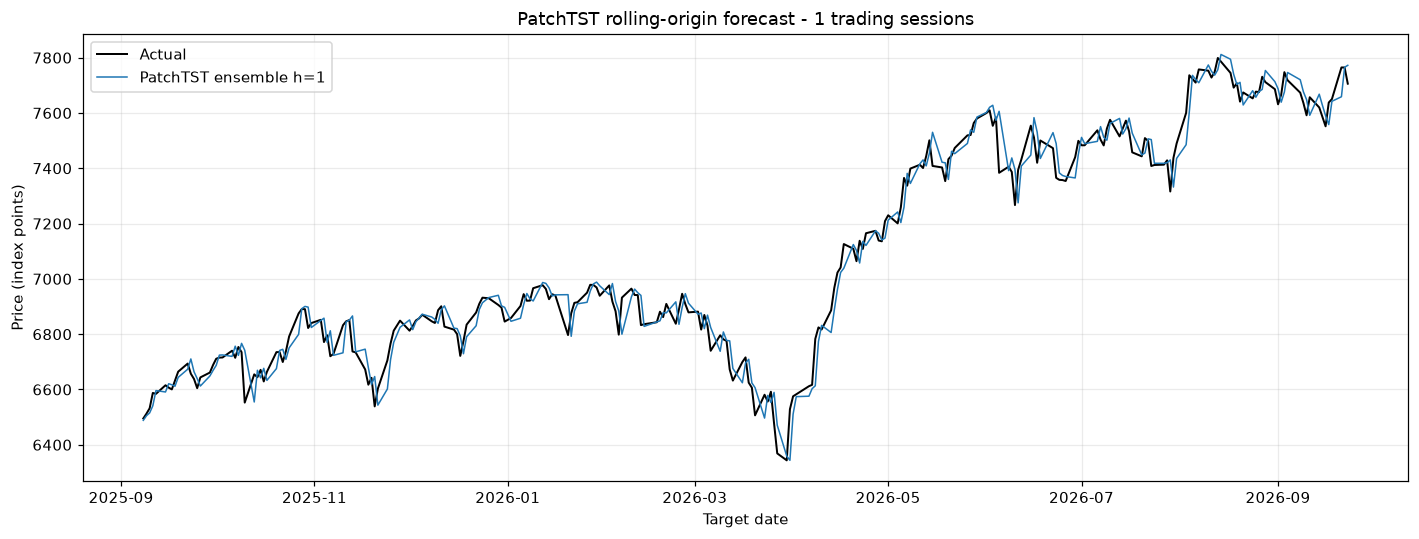

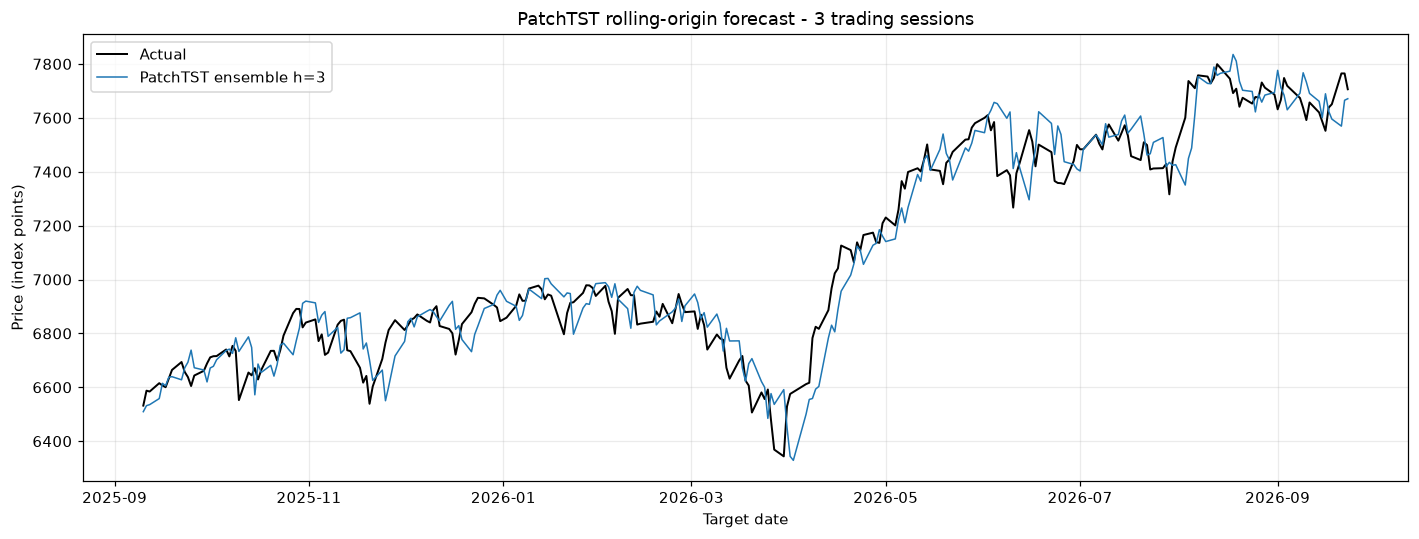

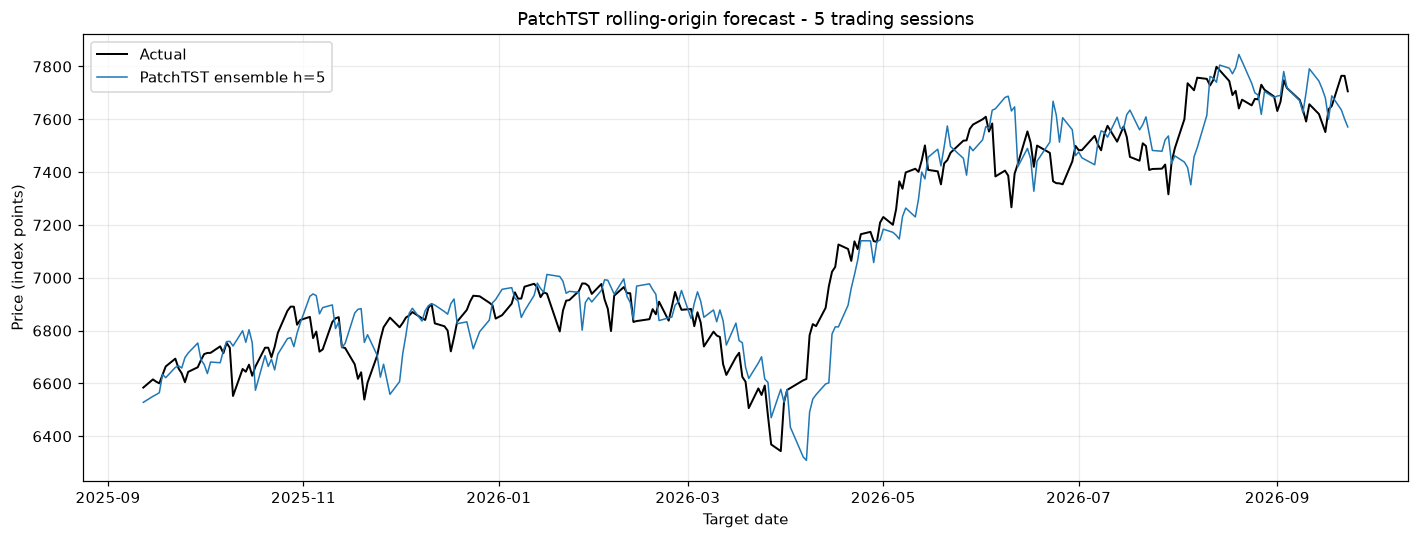

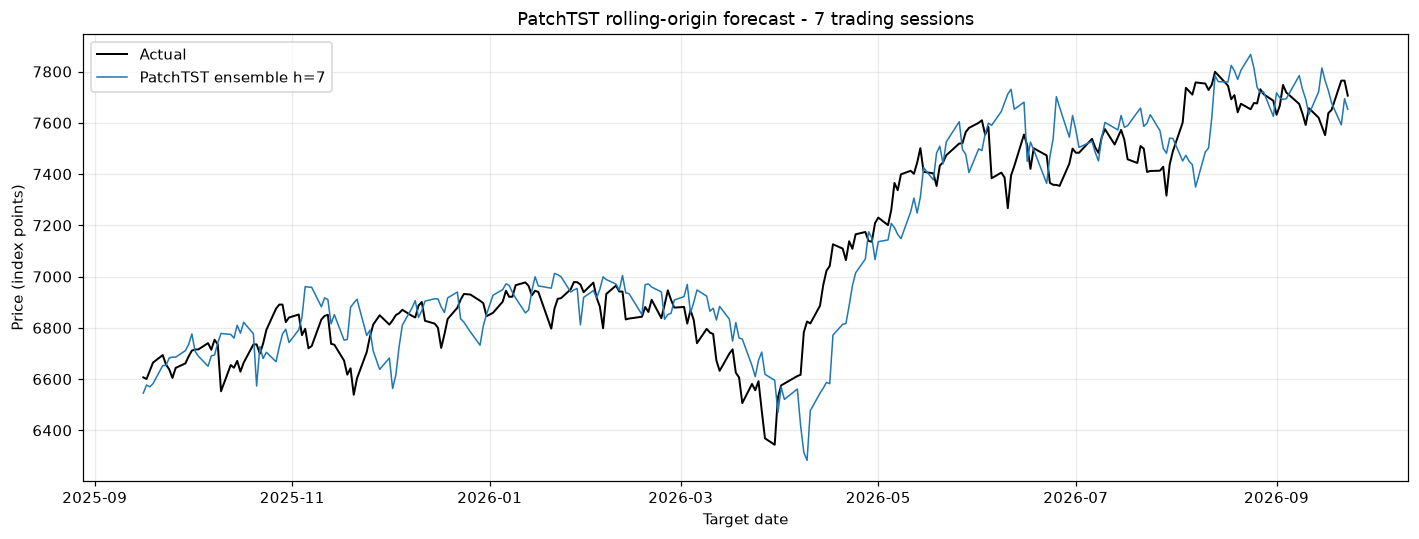

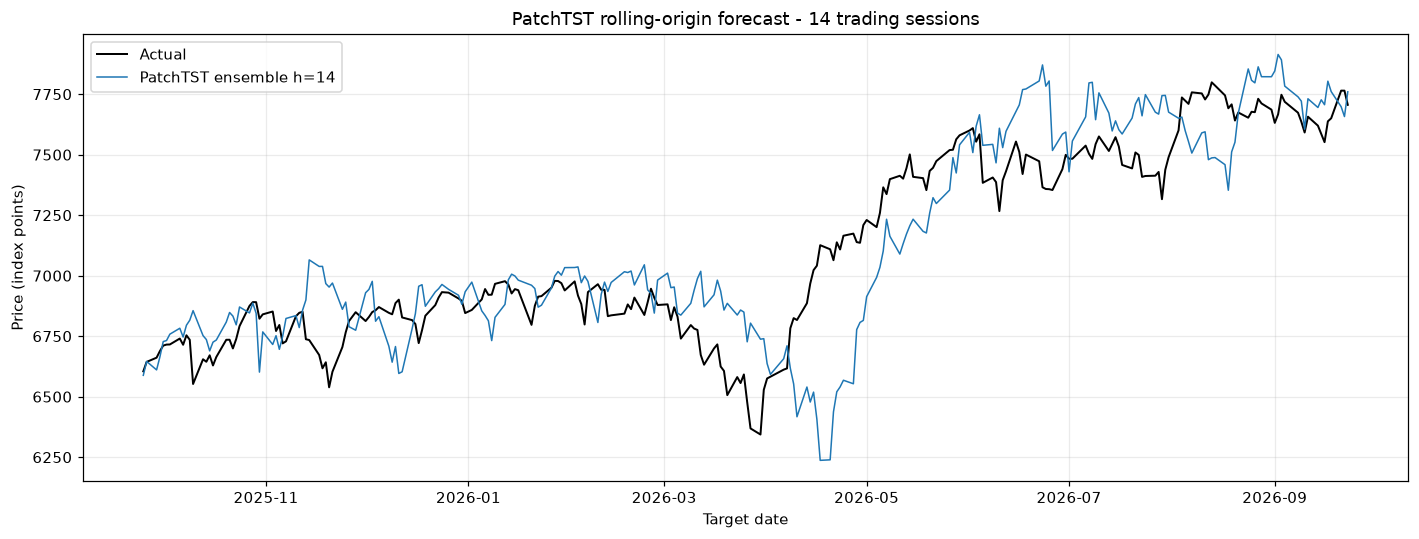

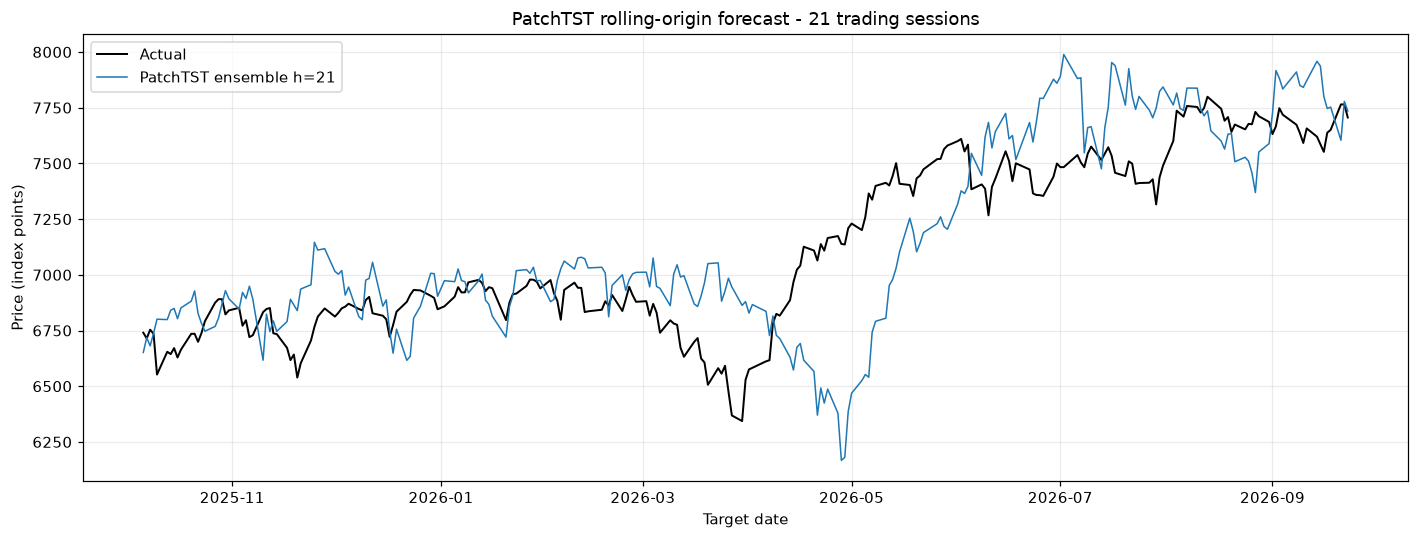

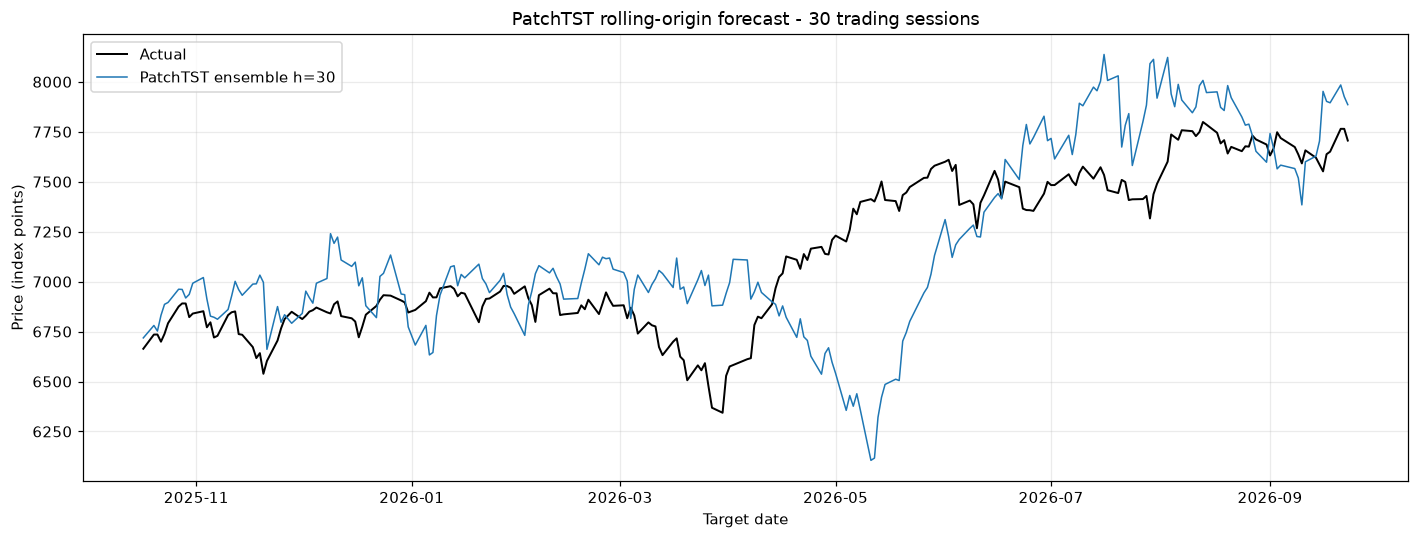

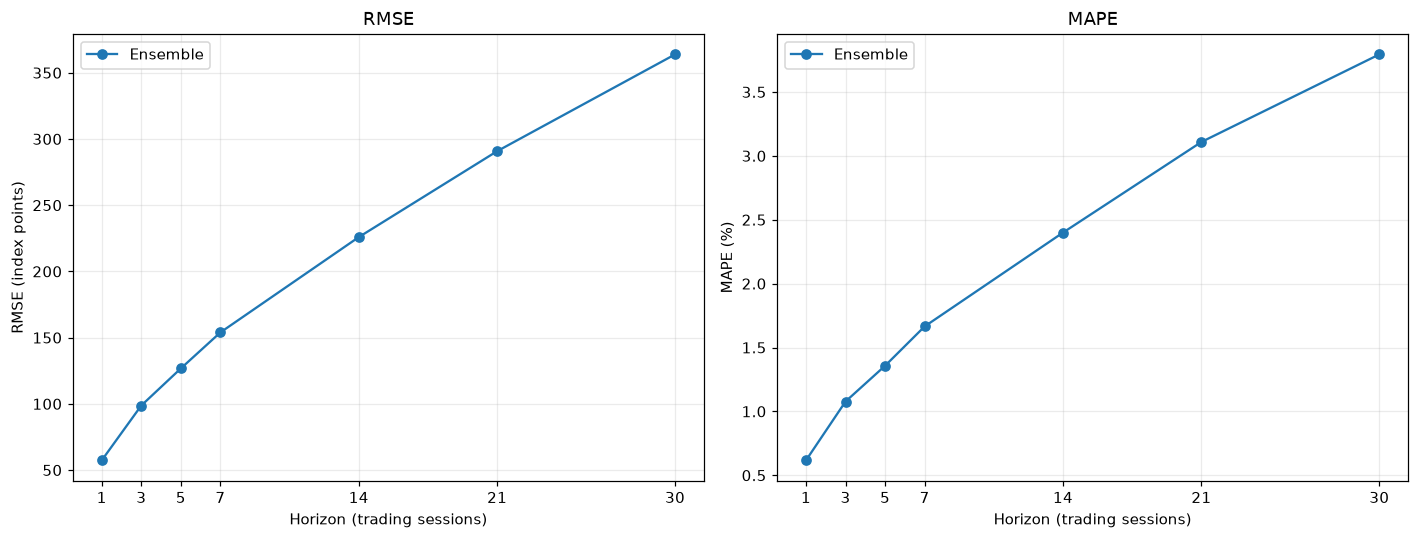

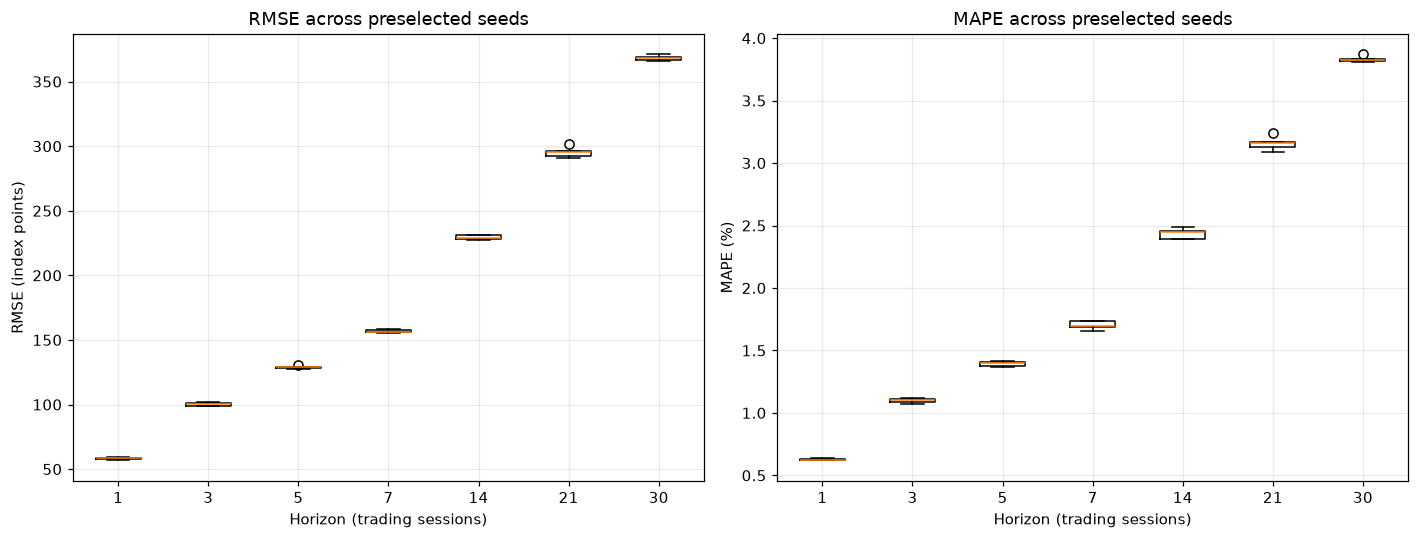

In [16]:
for h in HORIZONS:
    group = forecasts.loc[forecasts['h'].eq(h)]
    fig, ax = plt.subplots(figsize=(13, 5))
    ax.plot(group['target_date'], group['actual'], color='black', label='Actual', linewidth=1.3)
    ax.plot(group['target_date'], group['patchtst_fc_ens'], label=f'PatchTST ensemble h={h}', linewidth=1)
    ax.set(title=f'PatchTST rolling-origin forecast - {h} trading sessions', ylabel='Price (index points)', xlabel='Target date')
    ax.legend()
    save_figure(fig, f'07_forecast_h{h}.png')
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, metric, unit in zip(axes, ['RMSE','MAPE'], ['index points','%']):
    ax.plot(evaluation['h'], evaluation[metric], marker='o', label='Ensemble')
    ax.set(title=metric, xlabel='Horizon (trading sessions)', ylabel=f'{metric} ({unit})', xticks=HORIZONS)
    ax.legend()
save_figure(fig, '08_error_vs_horizon.png')
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, metric, unit in zip(axes, ['RMSE','MAPE'], ['index points','%']):
    values = [evaluation_seed_individual.loc[evaluation_seed_individual['h'].eq(h),metric].to_numpy()
              for h in HORIZONS]
    ax.boxplot(values, tick_labels=[str(h) for h in HORIZONS])
    ax.set(title=f'{metric} across preselected seeds', xlabel='Horizon (trading sessions)', ylabel=f'{metric} ({unit})')
save_figure(fig, '09_seed_variability.png')

## Step 11 - Process assumptions and residual diagnostics
Group A chronology, leakage, scaler provenance, patch geometry, fixed weights and finite training loss are checked; reduction is reported. Return-scale comparisons, parameters relative to training samples and variability across seeds are reported descriptively because no acceptable threshold was specified. They do not prove the absence of overfitting.

Group B uses h=1 Test ensemble session-return residuals only. Significant p-values describe limitations without changing the trained models; higher-horizon errors overlap naturally.

Group A finite-loss and structural checks are enforced. Loss reduction and distribution/seed stability are descriptive; no new threshold is imposed. Group B diagnoses h=1 Test log-return errors only and never changes the fitted design.

C:\Users\User\anaconda3\envs\vs_nine_tf\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


,group,check,statistic,p_value,pass/fail,note
0,A,Chronological unique dates,1.000000,NaN,PASS,
1,A,Train windows exclude test,1049.000000,NaN,PASS,All inputs/targets <= 1049
2,A,Scaler fit excludes test,1049.000000,NaN,PASS,
3,A,Fixed inference weights,1.000000,NaN,PASS,
4,A,Train/test return mean and SD,0.723120,NaN,REPORTED,"Train mean=0.000386768, SD=0.0111189; Test mea..."
5,A,Training loss reduced: seed 0,0.815173,NaN,REPORTED,First=1.40794; final=1.14772; reduced=True; fi...
6,A,Training loss reduced: seed 1,0.819252,NaN,REPORTED,First=1.41443; final=1.15878; reduced=True; fi...
7,A,Training loss reduced: seed 2,0.818398,NaN,REPORTED,First=1.42723; final=1.16804; reduced=True; fi...
8,A,Training loss reduced: seed 3,0.810837,NaN,REPORTED,First=1.43268; final=1.16167; reduced=True; fi...
9,A,Training loss reduced: seed 4,0.802609,NaN,REPORTED,First=1.41154; final=1.13291; reduced=True; fi...


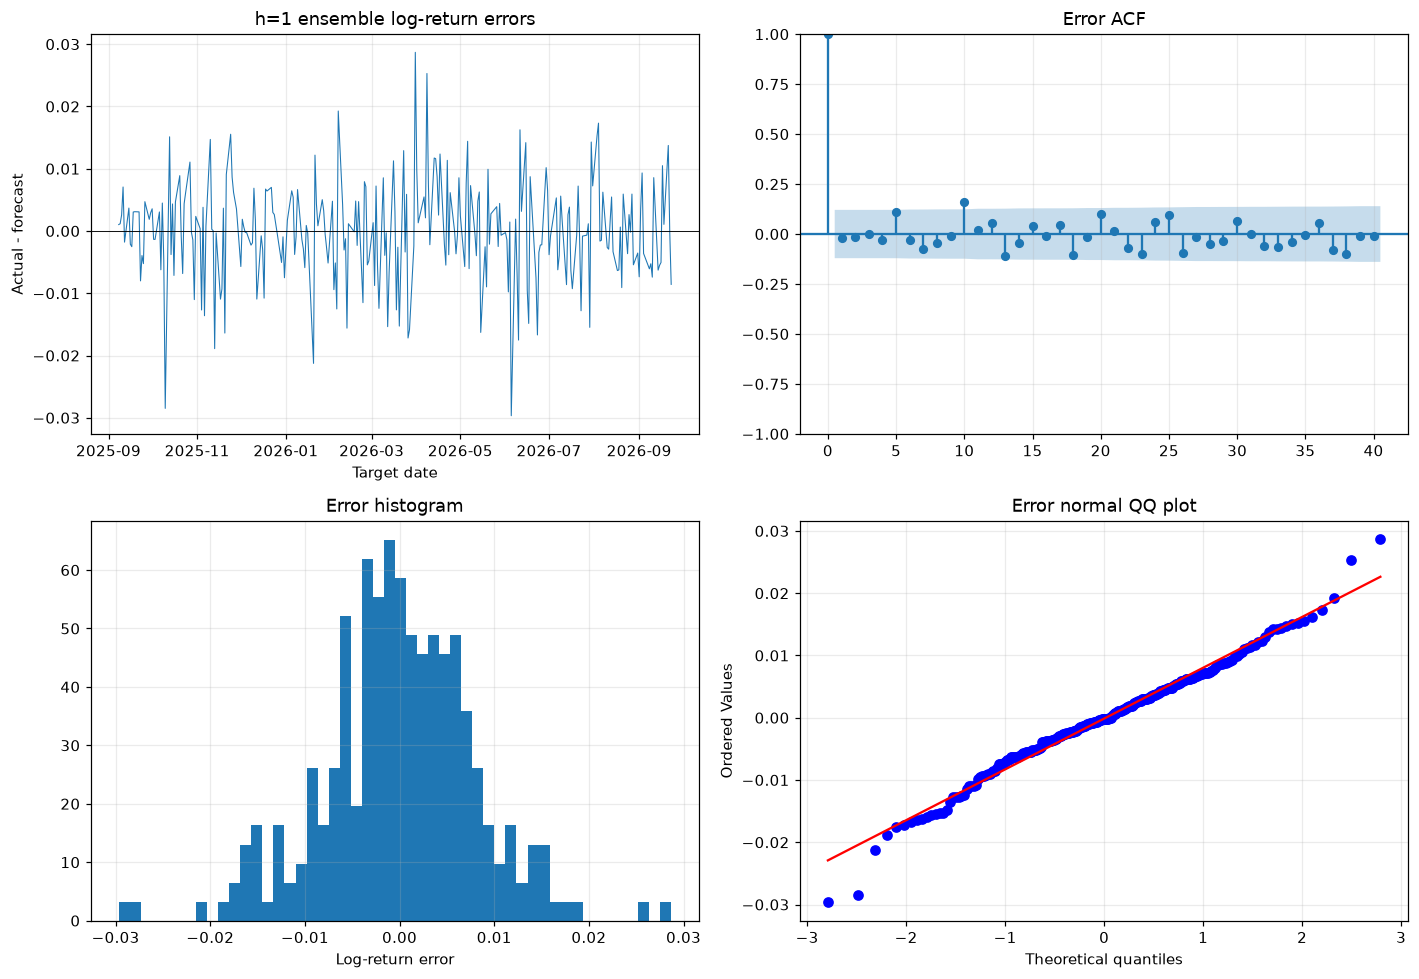

In [17]:
check_rows = []
def add_check(group, check, statistic=np.nan, p_value=np.nan, passed=None, note=''):
    status = 'REPORTED' if passed is None else ('PASS' if bool(passed) else 'FAIL')
    check_rows.append({'group':group, 'check':check, 'statistic':statistic,
                       'p_value':p_value, 'pass/fail':status, 'note':note})
ordered = df.index.is_monotonic_increasing and df.index.is_unique
no_leak = train_input_indices.max() <= TRAIN_END_IDX and train_target_indices.max() <= TRAIN_END_IDX
scaler_train_only = scaler_fit_indices.max() <= TRAIN_END_IDX and int(scaler.n_samples_seen_) == n_train-1
add_check('A','Chronological unique dates', int(ordered), passed=ordered)
add_check('A','Train windows exclude test', int(train_target_indices.max()), passed=no_leak,
          note=f'All inputs/targets <= {TRAIN_END_IDX}')
add_check('A','Scaler fit excludes test', int(scaler_fit_indices.max()), passed=scaler_train_only)
add_check('A','Fixed inference weights', int(weight_audit['unchanged'].all()), passed=weight_audit['unchanged'].all())
train_stats = split_summary.set_index('split').loc['Train']
test_stats = split_summary.set_index('split').loc['Test']
add_check('A','Train/test return mean and SD', float(test_stats['log_ret_std']/train_stats['log_ret_std']),
    note=f'Train mean={train_stats["log_ret_mean"]:.6g}, SD={train_stats["log_ret_std"]:.6g}; '
         f'Test mean={test_stats["log_ret_mean"]:.6g}, SD={test_stats["log_ret_std"]:.6g}. '
         'Statistic=Test/Train SD ratio; no acceptance threshold specified.')
for row in training_audit.itertuples(index=False):
    add_check('A',f'Training loss reduced: seed {row.seed}', row.final_loss/row.first_loss,
        passed=None, note=f'First={row.first_loss:.6g}; final={row.final_loss:.6g}; reduced={row.loss_reduced}; fixed {EPOCHS} epochs; reporting only')
for row in seed_summary.itertuples(index=False):
    add_check('A',f'Seed RMSE SD: h={row.h}', row.RMSE_SD,
              note=f'index points, sample SD across {len(SEEDS)} seeds; no threshold specified')
    add_check('A',f'Seed MAPE SD: h={row.h}', row.MAPE_SD,
              note=f'Percentage points, sample SD across {len(SEEDS)} seeds; no threshold specified')
patching_ok = patch_count==(LOOKBACK+STRIDE-PATCH_LEN)//STRIDE+1 and patches.shape[-2:]==(patch_count,PATCH_LEN)
add_check('A','Correct patch count and length',patch_count,passed=patching_ok,note=f'{patch_count} patches, each {PATCH_LEN} values')
add_check('A','Parameters relative to training samples',parameter_count/len(X_train),
    note=f'{parameter_count} trainable parameters vs {len(X_train)} windows; windows overlap; no pass threshold; overfit risk')
assert patching_ok
assert ordered and no_leak and scaler_train_only and weight_audit['unchanged'].all()
assert np.isfinite(seed_summary.select_dtypes('number').to_numpy()).all()

error_dates = df.index[test_origins+1]
e = log_ret.iloc[test_origins+1].to_numpy() - return_predictions_ens[:len(test_origins),0]
assert len(e) == n_test and np.isfinite(e).all()
ljung_box = acorr_ljungbox(e, lags=[10,20,30], return_df=True)
for lag,row in ljung_box.iterrows():
    add_check('B',f'Ljung-Box lag {lag}', row['lb_stat'], row['lb_pvalue'], row['lb_pvalue'] > ALPHA,
              'If significant, errors retain autocorrelation; reporting only')
mean_stat, mean_p = stats.ttest_1samp(e, 0)
add_check('B','Residual mean = 0', mean_stat, mean_p, mean_p > ALPHA,
          f'Mean error={e.mean():.6g}; if significant, forecast bias; reporting only')
arch_stat, arch_p, _, _ = het_arch(e, nlags=10)
add_check('B','ARCH LM (10 lags)', arch_stat, arch_p, arch_p > ALPHA,
          'If significant, error variance changes over time; reporting only')
jb_stat, jb_p, skew, kurt = jarque_bera(e)
add_check('B','Jarque-Bera', jb_stat, jb_p, jb_p > ALPHA,
          f'skew={skew:.4g}, kurtosis={kurt:.4g}; reporting only')
assumption_checks = pd.DataFrame(check_rows)
save_table(assumption_checks, 'assumption_checks.csv')
save_table(pd.DataFrame({'target_date':error_dates, 'actual_log_return':log_ret.iloc[test_origins+1].to_numpy(),
    'predicted_log_return':return_predictions_ens[:len(test_origins),0], 'residual':e}), 'residuals_h1.csv')
display(assumption_checks)
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes[0,0].plot(error_dates, e, linewidth=0.7)
axes[0,0].axhline(0, color='black', linewidth=0.6)
axes[0,0].set(title='h=1 ensemble log-return errors', xlabel='Target date', ylabel='Actual - forecast')
plot_acf(e, lags=40, ax=axes[0,1]); axes[0,1].set_title('Error ACF')
axes[1,0].hist(e, bins=50, density=True); axes[1,0].set(title='Error histogram', xlabel='Log-return error')
stats.probplot(e, dist='norm', plot=axes[1,1]); axes[1,1].set_title('Error normal QQ plot')
save_figure(fig, '10_residual_diagnostics.png')

## Step 12 - Summary from the executed results
PatchTST provides a standalone univariate Transformer design with local patch tokens and channel independence. Patching addresses some design concerns raised about time-series Transformers; it does not establish that a Transformer will outperform simpler methods on this dataset. The report below is generated from this execution and saved as Markdown.

In [18]:
FORECAST_COLUMN='patchtst_fc_ens'
lines = [f'### S&P 500 - {MODEL_LABEL} results from this execution', '',
    f'Data: {n:,} observed NYSE sessions, {df.index[0].date()} to {df.index[-1].date()}.',
    f'Raw Train/Test={n_train}/{n_test}; Train ends {df.index[TRAIN_END_IDX].date()}, Test starts {df.index[n_train].date()}.',
    f'Horizons={HORIZONS} trading sessions; inputs={LOOKBACK} past session returns; original target units=index points.',
    'No validation, cross-validation, Test tuning, early stopping, seed selection or all-data refit.',
    'Previously observed Test history updates inputs only; fitted parameters and preprocessing remain fixed.',
    '', '**Configuration fixed before Test evaluation**', '```json', json.dumps(configuration,indent=2,default=str), '```',
    '', '**Assumption/process checks**']
for row in assumption_checks.to_dict('records'):
    ptext=f', p={row["p_value"]:.6g}' if pd.notna(row['p_value']) else ''
    lines.append(f'- Group {row["group"]}: {row["check"]}: {row["pass/fail"]}{ptext}. {row["note"]}')
lines += ['', '**Historical Test performance**', '',
    '| Horizon (sessions) | Pairs | RMSE (index points) | MAPE (%) |','|---:|---:|---:|---:|']
for row in evaluation.itertuples(index=False):
    lines.append(f'| {row.h} | {row.n_points} | {row.RMSE:,.2f} | {row.MAPE:.2f} |')
if 'seed_summary' in globals():
    lines += ['', '**All predefined seeds: metric mean and sample SD (different from ensemble performance)**','',
        '| Horizon | Seed RMSE mean +/- SD (points) | Seed MAPE mean +/- SD (%) |','|---:|---:|---:|']
    for row in seed_summary.itertuples(index=False):
        lines.append(f'| {row.h} | {row.RMSE_mean:.2f} +/- {row.RMSE_SD:.2f} | {row.MAPE_mean:.2f} +/- {row.MAPE_SD:.2f} |')
lines += ['', '**Future forecasts: common latest observed origin, fixed Train model**']
for row in future_forecasts.to_dict('records'):
    lines.append(f'- h={row["h"]}: origin={row["origin_date"].date()}, target={row["target_date"].date()}, forecast={row[FORECAST_COLUMN]:,.2f} points.')
lines += ['', '**Limitations and interpretation**',
    '- Future means dates after the final CSV observation, not necessarily dates after today. These rows have no actuals or error metrics.',
    '- Train fit and loss reductions are optimistic fitting diagnostics, not proof of generalization. There is no independent validation estimate.',
    '- Group A structural checks enforce chronology/leakage/frozen state. Distribution comparisons, seed variability and loss-reduction summaries are descriptive where no threshold is supplied.',
    '- Group B h=1 log-return residual tests report autocorrelation, bias, changing variance and non-normality; significant results do not discard or retune models.',
    '- No ARIMA stationarity/root conditions are imposed on this model family.',
    '- Different horizons have different targets/counts and overlapping errors. MAPE is error percent; 100-MAPE is not statistical accuracy.',
    '- Univariate Price-derived returns do not observe news, policy changes, interest rates, inflation or unexpected events.',
    '- No calibrated prediction intervals are provided; seed dispersion, if present, is not a prediction interval.',
    '- All source rows are retained. Volume is missing and unused. No weekend/holiday observations or targets were imputed.',
    '- Session calendar covers 2021-2027 scheduled NYSE closures, including 9 January 2025; early-close days remain sessions. Unexpected closures can change future dates.',
    '- Tables, figures and this summary are embedded in this existing notebook; no additional files or model exports are written. Trained models remain in memory during the session.']
lines += ['', '**Daily future forecasts**', 'Tables for 7 and 30 future steps are shown before metrics; dates follow the existing asset calendar convention.']
summary_markdown='\n'.join(lines)
display(Markdown(summary_markdown))
# Final audits; no additional fitting or design revision.
assert n_train==int(0.8*n) and n_train+n_test==n
assert forecasts.groupby('h').size().to_dict()=={h:n_test-h+1 for h in HORIZONS}
assert not forecasts.duplicated(['origin_date','h']).any()
assert forecasts.target_date.between(df.index[n_train],df.index[-1]).all()
assert (df.index.get_indexer(forecasts.target_date)-df.index.get_indexer(forecasts.origin_date)==forecasts.h.to_numpy()).all()
assert (future_forecasts.origin_date==df.index[-1]).all()
assert future_forecasts.target_date.tolist()==[future_dates[h-1] for h in HORIZONS]
assert np.isfinite(evaluation[['RMSE','MAPE']]).all().all()
assert not len(missing_sessions) and not len(unexpected_dates)
assert not assumption_checks.loc[assumption_checks.group.eq('A'),'pass/fail'].eq('FAIL').any()
for name in ['split_summary.csv','calendar_audit.csv','forecasts_long.csv','evaluation_by_horizon.csv','future_forecast_by_horizon.csv','assumption_checks.csv',*[f'forecasts_h{h}.csv' for h in HORIZONS]]:
    assert name in notebook_tables,name
assert scaler_digest(scaler)==frozen_scaler_hash
assert all(weights_digest(models[seed])==frozen_weight_hashes[seed] for seed in SEEDS)
display(Markdown('### Full supplementary table archive (stored in this notebook)'))
for name, frame in notebook_tables.items():
    if name.startswith('forecasts') or name in ['evaluation_by_horizon.csv','future_forecast_by_horizon.csv','assumption_checks.csv','volume_B_rows.csv']:
        continue
    display(Markdown(f'**{name.removesuffix(".csv")}**'))
    show_scroll_table(frame)
print(f'Completed: {MODEL_LABEL}; {len(notebook_tables)} tables retained, {len(notebook_figures)} figures; all structural checks passed.')

### S&P 500 - Transformer (PatchTST) results from this execution

Data: 1,313 observed NYSE sessions, 2021-07-01 to 2026-09-23.
Raw Train/Test=1050/263; Train ends 2025-09-05, Test starts 2025-09-08.
Horizons=[1, 3, 5, 7, 14, 21, 30] trading sessions; inputs=60 past session returns; original target units=index points.
No validation, cross-validation, Test tuning, early stopping, seed selection or all-data refit.
Previously observed Test history updates inputs only; fitted parameters and preprocessing remain fixed.

**Configuration fixed before Test evaluation**
```json
{
  "HORIZONS": [
    1,
    3,
    5,
    7,
    14,
    21,
    30
  ],
  "MAX_H": 30,
  "LOOKBACK": 60,
  "TRAIN_RATIO": 0.8,
  "ALPHA": 0.05,
  "EPOCHS": 100,
  "BATCH_SIZE": 128,
  "LR": 0.0001,
  "DROPOUT": 0.3,
  "SEEDS": [
    0,
    1,
    2,
    3,
    4
  ],
  "PATCH_LEN": 16,
  "STRIDE": 8,
  "PADDING_PATCH": "end",
  "N_LAYERS": 3,
  "N_HEADS": 4,
  "D_MODEL": 16,
  "D_FF": 128,
  "FC_DROPOUT": 0.3,
  "HEAD_DROPOUT": 0.0,
  "REVIN": true,
  "PCT_START": 0.3,
  "DEVICE": "cpu",
  "asset": "S&P 500",
  "target": "Price",
  "units": "index points",
  "horizon_unit": "trading sessions",
  "validation": false,
  "output_mode": "notebook only",
  "source_reference": "BTC_TEST/TRANSFORMER_BTC.ipynb"
}
```

**Assumption/process checks**
- Group A: Chronological unique dates: PASS. 
- Group A: Train windows exclude test: PASS. All inputs/targets <= 1049
- Group A: Scaler fit excludes test: PASS. 
- Group A: Fixed inference weights: PASS. 
- Group A: Train/test return mean and SD: REPORTED. Train mean=0.000386768, SD=0.0111189; Test mean=0.000657989, SD=0.0080403. Statistic=Test/Train SD ratio; no acceptance threshold specified.
- Group A: Training loss reduced: seed 0: REPORTED. First=1.40794; final=1.14772; reduced=True; fixed 100 epochs; reporting only
- Group A: Training loss reduced: seed 1: REPORTED. First=1.41443; final=1.15878; reduced=True; fixed 100 epochs; reporting only
- Group A: Training loss reduced: seed 2: REPORTED. First=1.42723; final=1.16804; reduced=True; fixed 100 epochs; reporting only
- Group A: Training loss reduced: seed 3: REPORTED. First=1.43268; final=1.16167; reduced=True; fixed 100 epochs; reporting only
- Group A: Training loss reduced: seed 4: REPORTED. First=1.41154; final=1.13291; reduced=True; fixed 100 epochs; reporting only
- Group A: Seed RMSE SD: h=1: REPORTED. index points, sample SD across 5 seeds; no threshold specified
- Group A: Seed MAPE SD: h=1: REPORTED. Percentage points, sample SD across 5 seeds; no threshold specified
- Group A: Seed RMSE SD: h=3: REPORTED. index points, sample SD across 5 seeds; no threshold specified
- Group A: Seed MAPE SD: h=3: REPORTED. Percentage points, sample SD across 5 seeds; no threshold specified
- Group A: Seed RMSE SD: h=5: REPORTED. index points, sample SD across 5 seeds; no threshold specified
- Group A: Seed MAPE SD: h=5: REPORTED. Percentage points, sample SD across 5 seeds; no threshold specified
- Group A: Seed RMSE SD: h=7: REPORTED. index points, sample SD across 5 seeds; no threshold specified
- Group A: Seed MAPE SD: h=7: REPORTED. Percentage points, sample SD across 5 seeds; no threshold specified
- Group A: Seed RMSE SD: h=14: REPORTED. index points, sample SD across 5 seeds; no threshold specified
- Group A: Seed MAPE SD: h=14: REPORTED. Percentage points, sample SD across 5 seeds; no threshold specified
- Group A: Seed RMSE SD: h=21: REPORTED. index points, sample SD across 5 seeds; no threshold specified
- Group A: Seed MAPE SD: h=21: REPORTED. Percentage points, sample SD across 5 seeds; no threshold specified
- Group A: Seed RMSE SD: h=30: REPORTED. index points, sample SD across 5 seeds; no threshold specified
- Group A: Seed MAPE SD: h=30: REPORTED. Percentage points, sample SD across 5 seeds; no threshold specified
- Group A: Correct patch count and length: PASS. 7 patches, each 16 values
- Group A: Parameters relative to training samples: REPORTED. 19950 trainable parameters vs 960 windows; windows overlap; no pass threshold; overfit risk
- Group B: Ljung-Box lag 10: PASS, p=0.219915. If significant, errors retain autocorrelation; reporting only
- Group B: Ljung-Box lag 20: PASS, p=0.212254. If significant, errors retain autocorrelation; reporting only
- Group B: Ljung-Box lag 30: PASS, p=0.145479. If significant, errors retain autocorrelation; reporting only
- Group B: Residual mean = 0: PASS, p=0.787401. Mean error=-0.000136097; if significant, forecast bias; reporting only
- Group B: ARCH LM (10 lags): PASS, p=0.583157. If significant, error variance changes over time; reporting only
- Group B: Jarque-Bera: FAIL, p=0.000139568. skew=-0.1714, kurtosis=4.226; reporting only

**Historical Test performance**

| Horizon (sessions) | Pairs | RMSE (index points) | MAPE (%) |
|---:|---:|---:|---:|
| 1 | 263 | 57.35 | 0.62 |
| 3 | 261 | 98.74 | 1.08 |
| 5 | 259 | 126.74 | 1.36 |
| 7 | 257 | 153.93 | 1.66 |
| 14 | 250 | 225.90 | 2.40 |
| 21 | 243 | 290.80 | 3.11 |
| 30 | 234 | 363.87 | 3.79 |

**All predefined seeds: metric mean and sample SD (different from ensemble performance)**

| Horizon | Seed RMSE mean +/- SD (points) | Seed MAPE mean +/- SD (%) |
|---:|---:|---:|
| 1 | 58.17 +/- 1.02 | 0.63 +/- 0.01 |
| 3 | 100.27 +/- 1.39 | 1.10 +/- 0.02 |
| 5 | 128.90 +/- 1.33 | 1.39 +/- 0.02 |
| 7 | 156.71 +/- 1.35 | 1.70 +/- 0.03 |
| 14 | 229.43 +/- 1.99 | 2.43 +/- 0.04 |
| 21 | 295.33 +/- 4.20 | 3.16 +/- 0.06 |
| 30 | 368.27 +/- 1.95 | 3.83 +/- 0.02 |

**Future forecasts: common latest observed origin, fixed Train model**
- h=1: origin=2026-09-23, target=2026-09-24, forecast=7,708.11 points.
- h=3: origin=2026-09-23, target=2026-09-28, forecast=7,709.95 points.
- h=5: origin=2026-09-23, target=2026-09-30, forecast=7,724.71 points.
- h=7: origin=2026-09-23, target=2026-10-02, forecast=7,747.69 points.
- h=14: origin=2026-09-23, target=2026-10-13, forecast=7,792.45 points.
- h=21: origin=2026-09-23, target=2026-10-22, forecast=7,830.27 points.
- h=30: origin=2026-09-23, target=2026-11-04, forecast=7,857.11 points.

**Limitations and interpretation**
- Future means dates after the final CSV observation, not necessarily dates after today. These rows have no actuals or error metrics.
- Train fit and loss reductions are optimistic fitting diagnostics, not proof of generalization. There is no independent validation estimate.
- Group A structural checks enforce chronology/leakage/frozen state. Distribution comparisons, seed variability and loss-reduction summaries are descriptive where no threshold is supplied.
- Group B h=1 log-return residual tests report autocorrelation, bias, changing variance and non-normality; significant results do not discard or retune models.
- No ARIMA stationarity/root conditions are imposed on this model family.
- Different horizons have different targets/counts and overlapping errors. MAPE is error percent; 100-MAPE is not statistical accuracy.
- Univariate Price-derived returns do not observe news, policy changes, interest rates, inflation or unexpected events.
- No calibrated prediction intervals are provided; seed dispersion, if present, is not a prediction interval.
- All source rows are retained. Volume is missing and unused. No weekend/holiday observations or targets were imputed.
- Session calendar covers 2021-2027 scheduled NYSE closures, including 9 January 2025; early-close days remain sessions. Unexpected closures can change future dates.
- Tables, figures and this summary are embedded in this existing notebook; no additional files or model exports are written. Trained models remain in memory during the session.

**Daily future forecasts**
Tables for 7 and 30 future steps are shown before metrics; dates follow the existing asset calendar convention.

### Full supplementary table archive (stored in this notebook)

**library_versions**

library,version
pandas,2.3.3
numpy,2.5.3
matplotlib,3.11.1
scikit-learn,1.9.1
statsmodels,0.15.0
scipy,1.18.1
torch,2.14.1+cpu


**configuration_provenance**

...

**evaluation_by_seed**

h,seed,RMSE,MAPE
1,0,59.3932,0.6409
1,1,56.7965,0.6205
1,2,58.5059,0.6203
1,3,57.5066,0.6268
1,4,58.6280,0.6316
1,mean,58.1660,0.6280
1,SD,1.0180,0.0086
3,0,101.8008,1.1156
3,1,100.3378,1.1029
3,2,98.7045,1.0744


**residuals_h1**

target_date,actual_log_return,predicted_log_return,residual
2025-09-08,0.0021,0.0011,0.0010
2025-09-09,0.0027,0.0015,0.0012
2025-09-10,0.0030,0.0004,0.0026
2025-09-11,0.0085,0.0014,0.0071
2025-09-12,-0.0005,0.0013,-0.0018
2025-09-15,0.0047,0.0010,0.0037
2025-09-16,-0.0013,0.0008,-0.0021
2025-09-17,-0.0010,0.0015,-0.0025
2025-09-18,0.0048,0.0017,0.0030
2025-09-19,0.0049,0.0018,0.0031


Completed: Transformer (PatchTST); 26 tables retained, 16 figures; all structural checks passed.


## Implementation and calendar references

Local model example: `BTC_TEST/TRANSFORMER_BTC.ipynb`. The architecture, analytical rules or fixed estimator settings follow this source, with S&P session dates, data quality and index-point units adapted explicitly.

- [NYSE holidays and trading hours](https://www.nyse.com/trade/hours-calendars)
- [NYSE special closure on 9 January 2025](https://www.nyse.com/publicdocs/nyse/markets/american-options/rule-interpretations/2025/National_Day_of_Mourning_20250102.pdf)
- [PatchTST reference implementation](https://github.com/yuqinie98/PatchTST)

Referenced implementation material does not override the user's no-validation, no-Test-tuning protocol.